<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_RobustCircuitMetrics_Maouaki2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Robust quanvolutional networks from circuit metrics: expressibility, entangling capability and controlled-rotation gates (Maouaki et al., 2025) step by step

This notebook re-implements, runs and checks the experiments of

> Walid El Maouaki, Alberto Marchisio, Taoufik Said, Muhammad Shafique and Mohamed Bennai,
> "Designing Robust Quantum Neural Networks via Optimized Circuit Metrics",
> *Advanced Quantum Technologies* (2025), DOI [10.1002/qute.202400601](https://doi.org/10.1002/qute.202400601), arXiv:2411.11870v2.

**What the notebook does.** It builds the paper's *quanvolutional neural network* (QuNN: a fixed 4-qubit "quantum convolution" with a
2 x 2 kernel and stride 2, followed by a trainable dense softmax layer) and its classical twin (a fixed 4-filter `Conv2D`), for 18 of the 19
circuit templates of Sim et al. (2019). It measures the two circuit metrics of the paper (expressibility and Meyer-Wallach entangling
capability) *from the circuits themselves* and compares them with the paper's Table 1, trains one model per circuit on 1000 MNIST and 1000
Fashion-MNIST images, attacks every model with white-box **FGSM** and **PGD** over a range of perturbation strengths, and then repeats the paper's
four experiments: QuNN vs CNN (Fig. 5), low-to-high expressibility (Fig. 5), low-to-high entangling capability (Fig. 6), the
expressibility x entanglement combinations (Fig. 7), the `CRz` vs `CRx` gate pairs (Fig. 8, 9) and the average gradient magnitude (Table 3).
Every number printed at the end is put next to the paper's value with a verdict.

**How to run.** Open in Google Colab (CPU runtime is enough, no GPU, no quantum hardware, no API key), then *Runtime -> Run all*.
`FAST_MODE = True` (default in the configuration cell) finishes in about 10 minutes on a CPU and uses a reduced circuit set, fewer seeds and
fewer test images; set `FAST_MODE = False` for the full run (all 18 circuits, more seeds and test images, about an hour on a laptop CPU).
**What you get at the end:** circuit drawings of every architecture, a table of your own expressibility / entangling-capability values
next to the paper's, accuracy-vs-perturbation curves with error bars, the gradient-magnitude table, and a claim-by-claim verdict table.

## The paper in one page

**Problem.** Quantum neural networks can be fooled by adversarial examples just like classical ones. Can the *design of the quantum circuit*
make a quanvolutional network more robust? The authors look at three circuit properties: **expressibility** (how uniformly the circuit's
output states cover the Hilbert space; measured by the KL divergence between the circuit's fidelity histogram and the Haar-random one, lower KL =
higher expressibility), **entangling capability** (average Meyer-Wallach measure of the output states) and the **type of controlled rotation**
(`CRz` vs `CRx`).

**Model (Fig. 1, 4).** An image is cut into 2 x 2 patches with stride 2. Each patch (4 pixels in [0, 1]) is angle-encoded with one `RY(pixel)` per qubit on 4 qubits,
a fixed parameterised circuit ("Ansatz") from Sim et al. is applied, and `<Z_k>` of each qubit becomes one of 4 channels of a 14 x 14 feature map. The feature map is flattened and fed
to a dense layer with 10 softmax outputs. The convolutional layer is **not trained** (fixed feature extractor); only the dense layer is trained. The CNN twin has
`Conv2D(4 filters, 2x2, stride 2, relu)`, also fixed, followed by the same dense layer.

**Data and training.** MNIST and Fashion-MNIST, 28 x 28 grey images scaled to [0, 1]; 1000 training samples, 30 epochs, batch size 4, Adam with learning rate 0.001,
sparse categorical cross-entropy. 10 independent runs per experiment, mean and error bars plotted.

**Attacks.** White-box FGSM (epsilon from 0 to 1; "low" 0-0.4, "high" 0.6-1) and PGD (epsilon 0 to 0.1; "low" 0-0.04, "high" 0.06-0.1) from CleverHans. Accuracy is plotted against epsilon.

**Claims (to be checked below).**
1. QuNNs are more robust than CNNs ("up to 60 % greater robustness on MNIST and 40 % on Fashion-MNIST").
2. Higher expressibility gives higher robustness, especially at low perturbation strength (Ansatz 9, 15, 13, 14, 6).
3. Lower entangling capability gives higher robustness at all strengths (Ansatz 1, 3, 19, 2, 9).
4. Combination: Ansatz 3 (low entanglement, decent expressibility) is best, Ansatz 1 close behind, Ansatz 9 (high entanglement, low expressibility) is worst, Ansatz 6 is hurt by its entanglement.
5. `CRz` circuits are generally more robust than their `CRx` partners (pairs 3-4, 5-6, 7-8, 13-14, 16-17, 18-19).
6. Average gradient magnitude (Table 3): CNN 1.7965, Ansatz 3 0.7650, Ansatz 9 3.8145, Ansatz 1 0.8249, Ansatz 6 1.5437; lower AGM goes with higher robustness.
7. Table 1: expressibility and entangling capability of the 18 circuits.

### What follows the paper and what had to be chosen

The paper gives the model, the data, the training recipe and the attack families, but the 19 circuit templates are only shown as pictures (Fig. 10, taken from Sim et al.), the PGD settings are not given, and the
code is not public. Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit templates | Fig. 10 (pictures), "adapted from Sim et al. 2019" | Re-built from Sim et al.'s Fig. 2 (4 qubits, one layer); **checked** by recomputing Table 1 (entangling capability matches within about 0.02 for all 18 circuits; expressibility less exactly, see section 5). Ansatz 11 and 12 are the `CNOT` and `CZ` circuits of Sim et al. (Table 1 of the paper labels them `CRz`/`CRx`) |
| Encoding | one `RY` per qubit, pixel in [0, 1] used as the angle in radians | same |
| Ansatz parameters of the (non-trainable) quanvolution | not stated | one fixed random draw per run, uniform in [0, 2 pi) (`# CHOICE`) |
| Classical twin | `Conv2D`, 4 filters, 2x2, stride 2, relu, non-trainable | same, Keras Glorot-uniform kernel, no bias, a new random draw per run |
| Dense head, optimiser | 10 softmax units, Adam lr 0.001, sparse CE, batch 4, 30 epochs | same, written in NumPy (Keras Glorot init, Adam beta 0.9/0.999, eps 1e-7) instead of Keras, so no TensorFlow is needed |
| Training set | 1000 samples per dataset | 1000 class-balanced random images of the official training split (100 per class), the same subset in every run (`# CHOICE`) |
| Test images for the attacks | not stated | random subset of the official test split (`N_TEST`, `# CHOICE`; 100 in FAST_MODE, 150 in the full run) |
| FGSM | CleverHans, epsilon 0-1, clipped to [0, 1] | exact analytic gradient (checked against finite differences), grid `FGSM_EPS` (`# CHOICE` of the grid) |
| PGD | CleverHans, epsilon 0-0.1 | L-infinity PGD, `PGD_ITERS` steps of size `2.5 eps / iters`, no random start, clipped to [0, 1] (`# CHOICE`: iterations, step, grid) |
| Independent runs | 10 | `N_SEEDS` (2 in FAST_MODE, 5 in the full run, `# CHOICE` to fit a CPU budget) |
| Expressibility | KL to Haar, fidelity histogram | 75 bins, `N_PAIRS` random state pairs, exact Haar bin masses for 4 qubits |
| Entangling capability | mean Meyer-Wallach | mean over `N_PAIRS` random parameter draws, parameters uniform in [0, 2 pi) |
| Average gradient magnitude | Table 3, definition not given | mean over test images of the mean absolute pixel gradient of the cross-entropy loss, also the L2 norm (`# CHOICE`); MNIST only, as in the paper |
| Simulator | simulator (PennyLane/TensorFlow Quantum style) | exact statevector maths in NumPy, **asserted equal** to Qiskit `Statevector` expectation values of the drawn circuits (section 3) |

In [1]:
# --- installs, pinned to the versions this notebook was tested with. Qiskit is used to draw the circuits and to
# --- cross-check the NumPy simulator. Colab already ships numpy, pandas, scikit-learn, matplotlib and scipy.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
if IN_COLAB or not (_have("qiskit") and _have("pylatexenc")):
    !pip -q install "qiskit==2.5.2" pylatexenc
    # a runtime restart is normally NOT needed for this notebook; if an import below fails, restart once and Run all again

In [2]:
# ----------------------------------------------- configuration: every tunable constant lives here -----------------------------------------------
SEED = 42
FAST_MODE = False            # True: about 10 minutes on a CPU; False: full run (all 18 circuits, more seeds / test images), see the budgets below
IBM_TOKEN = ""              # not used: all circuits are simulated exactly (4 qubits); kept for symmetry with the other notebooks

DATA_DIR = "qc154_data"     # MNIST / Fashion-MNIST files are cached here (or upload them into this folder)
DATASETS = ["MNIST", "FMNIST"]

# training recipe from the paper
N_TRAIN, BATCH_SIZE, LR = 1000, 4, 1e-3
EPOCHS      = 10 if FAST_MODE else 30                 # paper: 30
N_SEEDS     = 2  if FAST_MODE else 5                  # paper: 10 independent runs (CHOICE: fewer, CPU budget)
N_TEST      = 100 if FAST_MODE else 150               # CHOICE: test images attacked per run

# attacks
FGSM_EPS    = [0.0, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0]        # paper: low 0-0.4, high 0.6-1
PGD_EPS     = [0.0, 0.02, 0.04, 0.06, 0.1]        # paper: low 0-0.04, high 0.06-0.1
PGD_ITERS   = 5 if FAST_MODE else 10                  # CHOICE (not given in the paper)

# circuit metrics
N_PAIRS     = 5000 if FAST_MODE else 20000            # random parameter draws for expressibility / entangling capability (Sim et al. use thousands)
N_BINS      = 75

# which circuits are trained / attacked
ALL_ANSATZ  = [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 17, 18, 19]       # the 18 circuits of the paper's Table 1
FAST_ANSATZ = [1, 2, 3, 6, 9, 13, 14, 15, 19]                                         # union of the paper's three gradational experiments
ATTACK_ANSATZ = FAST_ANSATZ if FAST_MODE else ALL_ANSATZ

# Full-run budget (FAST_MODE=False): 18 circuits + CNN, 2 datasets, 5 seeds, 150 test images, 30 epochs, PGD 10 iterations.

In [3]:
import os, time, math, warnings, itertools, gzip, io
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import requests, scipy
from scipy.stats import spearmanr
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp
warnings.filterwarnings("ignore", category=DeprecationWarning)

rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| qiskit", qiskit.__version__)
print("FAST_MODE =", FAST_MODE, "| circuits:", ATTACK_ANSATZ, "| seeds:", N_SEEDS, "| test images:", N_TEST, "| epochs:", EPOCHS)

numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | qiskit 2.5.2
FAST_MODE = False | circuits: [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 17, 18, 19] | seeds: 5 | test images: 150 | epochs: 30


## 1. Data: MNIST and Fashion-MNIST

Both datasets are public. MNIST (handwritten digits) and Fashion-MNIST (ten clothing classes) consist of 28 x 28 grey-scale images with 60 000 training and 10 000 test examples each.
The notebook downloads the original files from public mirrors (Google's Keras mirror first, GitHub for Fashion-MNIST as a fallback, then the Hugging Face datasets
`ylecun/mnist` and `zalando-datasets/fashion_mnist`) and caches them in `DATA_DIR`; you can also upload `mnist.npz` / the four Fashion-MNIST `.gz` files into that folder by hand.
The Hugging Face fallback uses a token only if one exists in `HF_TOKEN` (environment variable, or Colab *Settings -> Secrets*); these two datasets are **not gated**, so no token is needed.

As in the paper, pixels are scaled to [0, 1] and **1000** training images are used (here: 100 random images per class). The attacked test images are a random subset of the official test split.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

CLASS_NAMES = {
    "MNIST": [str(i) for i in range(10)],
    "FMNIST": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"],
}
FULL_NAME = {"MNIST": "MNIST", "FMNIST": "Fashion-MNIST"}

def _download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return path
        except Exception as e:
            last = e
    raise RuntimeError(f"could not download any of {urls}: {last}")

def _read_idx(path):
    with gzip.open(path, "rb") as f: b = f.read()
    if b[2] == 8 and b[3] == 3:
        n, r, c = np.frombuffer(b[4:16], ">i4")
        return np.frombuffer(b, np.uint8, offset=16).reshape(n, r, c)
    return np.frombuffer(b, np.uint8, offset=8)

def _hf_parquet(repo, files):
    from huggingface_hub import hf_hub_download
    out = []
    for fn in files:
        p = hf_hub_download(repo, fn, repo_type="dataset", token=HF_TOKEN or None, local_dir=os.path.join(DATA_DIR, "hf_" + repo.replace("/", "_")))
        df = pd.read_parquet(p)
        from PIL import Image
        X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
        out.append((X, df["label"].to_numpy()))
    return out

def load_raw(name, force_hf=False):
    """Returns (x_train, y_train, x_test, y_test) as uint8 images and integer labels."""
    if name == "MNIST":
        if not force_hf:
            try:
                p = _download(["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
                               "https://s3.amazonaws.com/img-datasets/mnist.npz"], os.path.join(DATA_DIR, "mnist.npz"))
                d = np.load(p); return d["x_train"], d["y_train"], d["x_test"], d["y_test"]
            except Exception as e:
                print("primary MNIST mirror failed, using Hugging Face:", e)
        (xt, yt), (xe, ye) = _hf_parquet("ylecun/mnist", ["mnist/train-00000-of-00001.parquet", "mnist/test-00000-of-00001.parquet"])
        return xt, yt, xe, ye
    if not force_hf:
        try:
            names = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
            paths = [_download(["https://storage.googleapis.com/tensorflow/tf-keras-datasets/" + n,
                                "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/" + n],
                               os.path.join(DATA_DIR, "fmnist_" + n)) for n in names]
            return _read_idx(paths[0]), _read_idx(paths[1]), _read_idx(paths[2]), _read_idx(paths[3])
        except Exception as e:
            print("primary Fashion-MNIST mirror failed, using Hugging Face:", e)
    (xt, yt), (xe, ye) = _hf_parquet("zalando-datasets/fashion_mnist", ["fashion_mnist/train-00000-of-00001.parquet", "fashion_mnist/test-00000-of-00001.parquet"])
    return xt, yt, xe, ye

def stratified_subset(y, n_total, rng):
    per = n_total // 10
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), per, replace=False) for c in range(10)])
    return rng.permutation(idx)

DATA = {}
for ds in DATASETS:
    xtr_all, ytr_all, xte_all, yte_all = load_raw(ds)
    r = np.random.default_rng(SEED + (0 if ds == "MNIST" else 1))
    tr = stratified_subset(ytr_all, N_TRAIN, r)                       # CHOICE: 100 images per class
    te = r.choice(len(yte_all), 2000, replace=False)                  # a fixed pool of 2000 test images; the first N_TEST are attacked
    DATA[ds] = dict(Xtr=xtr_all[tr] / 255.0, ytr=ytr_all[tr].astype(int), Xte=xte_all[te][:N_TEST] / 255.0, yte=yte_all[te][:N_TEST].astype(int),
                    Xte_pool=xte_all[te] / 255.0, yte_pool=yte_all[te].astype(int), full_train_counts=np.bincount(ytr_all, minlength=10),
                    full_test_counts=np.bincount(yte_all, minlength=10), shape_full=(xtr_all.shape, xte_all.shape))
    print(f"{FULL_NAME[ds]}: full train {xtr_all.shape}, full test {xte_all.shape} -> training subset {DATA[ds]['Xtr'].shape}, attacked test subset {DATA[ds]['Xte'].shape}")
    del xtr_all, ytr_all, xte_all, yte_all

MNIST: full train (60000, 28, 28), full test (10000, 28, 28) -> training subset (1000, 28, 28), attacked test subset (150, 28, 28)


Fashion-MNIST: full train (60000, 28, 28), full test (10000, 28, 28) -> training subset (1000, 28, 28), attacked test subset (150, 28, 28)


## Dataset Exploration and Visualisation

Before any quantum circuit is used, the real data is inspected: its shape, its features (here the 784 grey values of a 28 x 28 image, as in the paper), the original label values and
class counts, the class distribution, example images, and a 2-D scatter of **real observations** coloured by their **ground-truth label**. The scatter has two panels:
the first two principal components of the raw pixels (PCA fitted on the training split only), and the same coordinates rescaled to [0, pi] (the range an angle encoding would use;
the model in this paper encodes each *pixel* in [0, 1] radians, so this second panel only shows what the scaling does to the point cloud).

MNIST: image array shape (28, 28) = 784 features (pixel grey values, scaled to [0, 1]); min 0.00, max 1.00, mean 0.133
feature names: pixel_r_c for row r, column c (r, c = 0..27), e.g. pixel_0_0 ... pixel_27_27
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


,class,full train (60000),full test (10000),training subset (1000),attacked test subset (150)
0,0,5923,980,100,13
1,1,6742,1135,100,10
2,2,5958,1032,100,24
3,3,6131,1010,100,15
4,4,5842,982,100,15
5,5,5421,892,100,15
6,6,5918,958,100,10
7,7,6265,1028,100,13
8,8,5851,974,100,17
9,9,5949,1009,100,18


Fashion-MNIST: image array shape (28, 28) = 784 features (pixel grey values, scaled to [0, 1]); min 0.00, max 1.00, mean 0.290
feature names: pixel_r_c for row r, column c (r, c = 0..27), e.g. pixel_0_0 ... pixel_27_27
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


,class,full train (60000),full test (10000),training subset (1000),attacked test subset (150)
0,T-shirt/top,6000,1000,100,17
1,Trouser,6000,1000,100,14
2,Pullover,6000,1000,100,15
3,Dress,6000,1000,100,11
4,Coat,6000,1000,100,12
5,Sandal,6000,1000,100,15
6,Shirt,6000,1000,100,19
7,Sneaker,6000,1000,100,10
8,Bag,6000,1000,100,22
9,Ankle boot,6000,1000,100,15


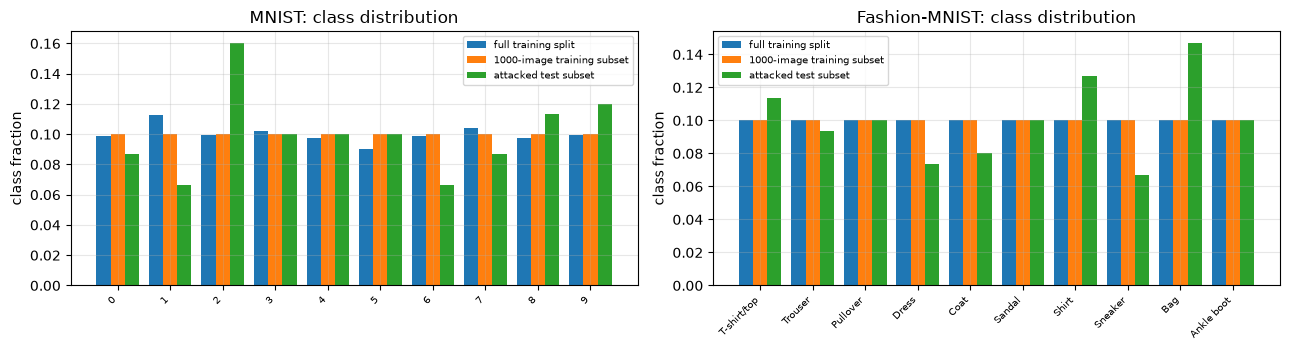

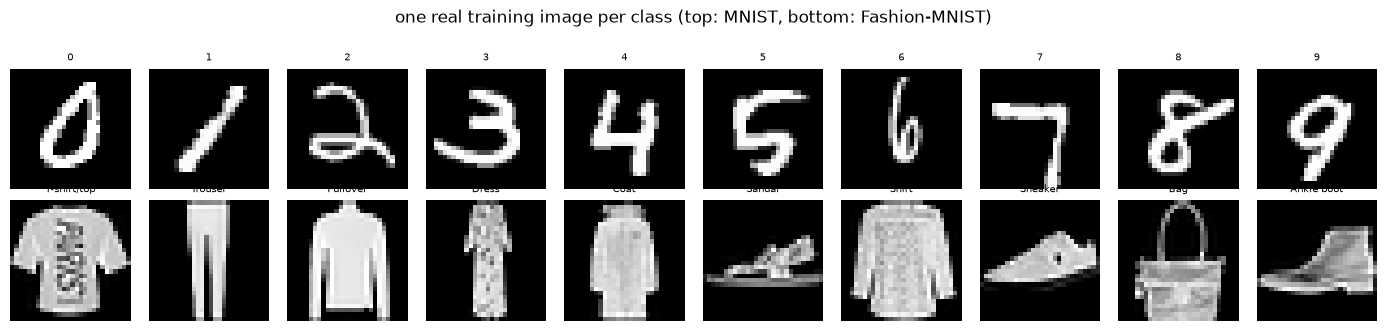

In [5]:
for ds in DATASETS:
    D = DATA[ds]
    print("=" * 100)
    print(f"{FULL_NAME[ds]}: image array shape {D['Xtr'].shape[1:]} = {D['Xtr'].shape[1] * D['Xtr'].shape[2]} features (pixel grey values, scaled to [0, 1]); "
          f"min {D['Xtr'].min():.2f}, max {D['Xtr'].max():.2f}, mean {D['Xtr'].mean():.3f}")
    print("feature names: pixel_r_c for row r, column c (r, c = 0..27), e.g. pixel_0_0 ... pixel_27_27")
    print("original label values:", sorted(set(D['ytr'].tolist())), "->", CLASS_NAMES[ds])
    cnt = pd.DataFrame({"class": CLASS_NAMES[ds], "full train (60000)": D["full_train_counts"], "full test (10000)": D["full_test_counts"],
                        f"training subset ({len(D['ytr'])})": np.bincount(D["ytr"], minlength=10), f"attacked test subset ({len(D['yte'])})": np.bincount(D["yte"], minlength=10)})
    display(cnt)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, ds in zip(axes, DATASETS):
    D = DATA[ds]; w = 0.27; xs = np.arange(10)
    ax.bar(xs - w, D["full_train_counts"] / D["full_train_counts"].sum(), w, label="full training split")
    ax.bar(xs, np.bincount(D["ytr"], minlength=10) / len(D["ytr"]), w, label="1000-image training subset")
    ax.bar(xs + w, np.bincount(D["yte"], minlength=10) / len(D["yte"]), w, label="attacked test subset")
    ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES[ds], rotation=45, ha="right", fontsize=7); ax.set_ylabel("class fraction"); ax.set_title(f"{FULL_NAME[ds]}: class distribution"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for r_, ds in enumerate(DATASETS):
    D = DATA[ds]
    for c in range(10):
        i = np.flatnonzero(D["ytr"] == c)[0]
        axes[r_, c].imshow(D["Xtr"][i], cmap="gray", vmin=0, vmax=1); axes[r_, c].axis("off"); axes[r_, c].set_title(CLASS_NAMES[ds][c], fontsize=7)
plt.suptitle("one real training image per class (top: MNIST, bottom: Fashion-MNIST)", y=1.02); plt.tight_layout(); plt.show()

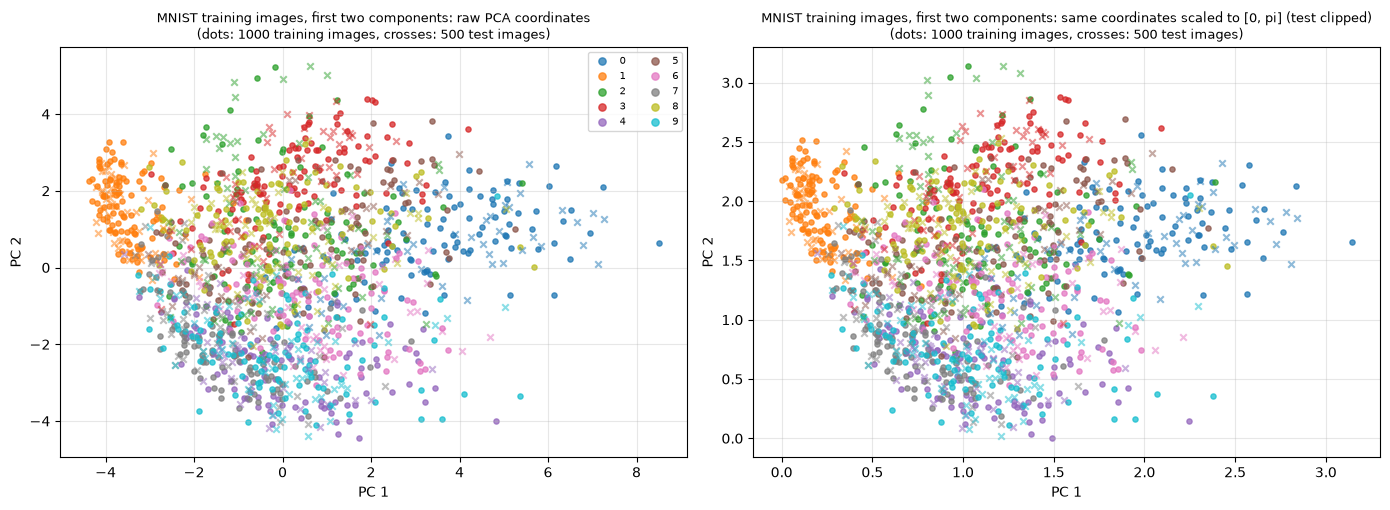

MNIST: variance explained by the two components = 16.6% (the 2-D view is a projection of 784 dimensions; classes overlap strongly in it)


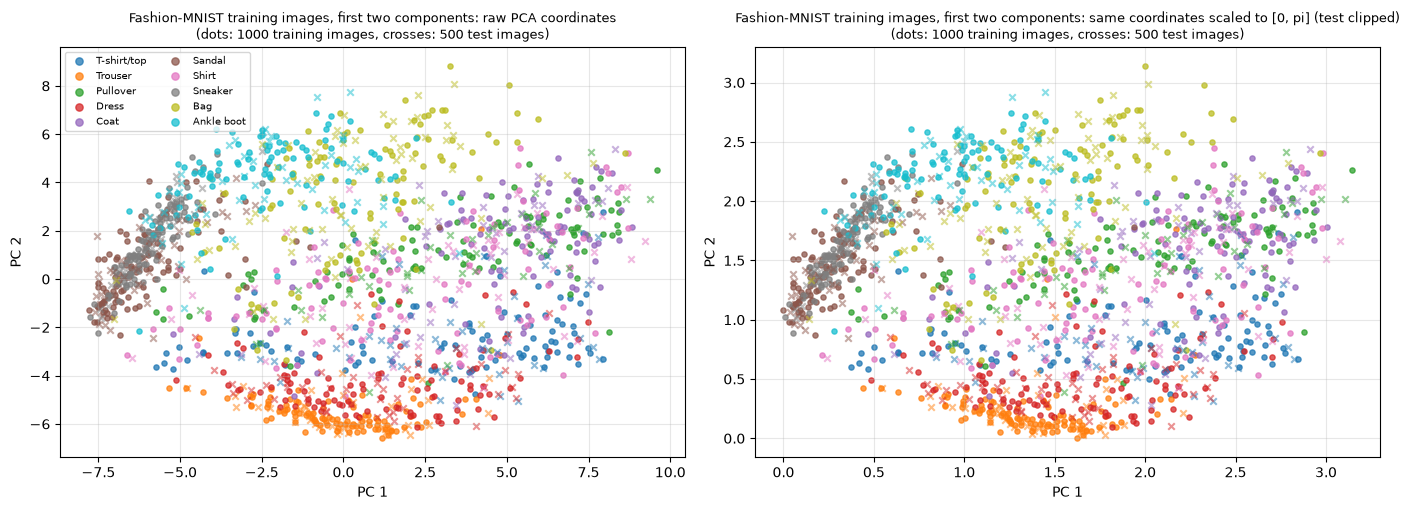

Fashion-MNIST: variance explained by the two components = 46.8% (the 2-D view is a projection of 784 dimensions; classes overlap strongly in it)


In [6]:
# 2-D scatter of real observations coloured by ground-truth label. PCA is fitted on the training subset only (test points are projected).
cmap = plt.get_cmap("tab10")
for ds in DATASETS:
    D = DATA[ds]
    pca = PCA(n_components=2, random_state=SEED).fit(D["Xtr"].reshape(len(D["Xtr"]), -1))
    Ztr = pca.transform(D["Xtr"].reshape(len(D["Xtr"]), -1)); Zte = pca.transform(D["Xte_pool"][:500].reshape(500, -1))
    sc = MinMaxScaler((0, np.pi)).fit(Ztr)                                  # fitted on the training split only
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    for ax, (A, B, ttl) in zip(axes, [(Ztr, Zte, "raw PCA coordinates"), (sc.transform(Ztr), np.clip(sc.transform(Zte), 0, np.pi), "same coordinates scaled to [0, pi] (test clipped)")]):
        for c in range(10):
            m = D["ytr"] == c; ax.scatter(A[m, 0], A[m, 1], s=14, color=cmap(c), alpha=0.75, label=CLASS_NAMES[ds][c])
        for c in range(10):
            m = D["yte_pool"][:500] == c; ax.scatter(B[m, 0], B[m, 1], s=22, marker="x", color=cmap(c), alpha=0.5)
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(f"{FULL_NAME[ds]} training images, first two components: {ttl}\n(dots: 1000 training images, crosses: 500 test images)", fontsize=9)
    axes[0].legend(fontsize=7, ncol=2, markerscale=1.4)
    plt.tight_layout(); plt.show()
    print(f"{FULL_NAME[ds]}: variance explained by the two components = {pca.explained_variance_ratio_.sum():.1%} (the 2-D view is a projection of 784 dimensions; classes overlap strongly in it)")

## 2. The 19 circuit templates and an exact simulator

The paper takes its "Ansatzes" from Sim, Johnson and Aspuru-Guzik (2019, *Expressibility and entangling capability of parameterized quantum circuits*, Fig. 2): 19 four-qubit, one-layer
templates built from `RX`, `RY`, `RZ` rotations, `H`, `CNOT`, `CZ` and the controlled rotations `CRx`, `CRz`. The paper uses 18 of them (circuit 10 is skipped) and shows them only as pictures.
The function `ansatz_ops(k)` below writes circuit *k* as a plain list of gates. **Every parameterised gate has its own free angle** (as in Sim et al.).
Circuits 3-4, 5-6, 7-8, 13-14, 16-17, 18-19 are `CRz`/`CRx` partners with identical structure.

Two representations of the *same* gate list are used:

* a small batched **NumPy statevector simulator** (`run_ops`) that is fast enough for thousands of random parameter draws and for 196 patches x many images, and
* a **Qiskit circuit** (built in section 3 from the same list) that is drawn and used to cross-check the simulator with an assertion.

In [7]:
# ------------------------------------------------------------ circuit templates (Sim et al. 2019, Fig. 2), 4 qubits, one layer ------------------------------------------------------------
# A gate is ("rx"|"ry"|"rz", q) with a free angle, ("crx"|"crz", control, target) with a free angle, ("cx"|"cz", control, target) or ("h", q).
def _rxrz(qs): return [(g, q) for q in qs for g in ("rx", "rz")]
def _ryrz(qs): return [(g, q) for q in qs for g in ("ry", "rz")]
def _ry(qs):   return [("ry", q) for q in qs]
def _rx(qs):   return [("rx", q) for q in qs]

def ansatz_ops(k):
    A = range(4)
    if k == 1:  return _rxrz(A)
    if k == 2:  return _rxrz(A) + [("cx", 3, 2), ("cx", 2, 1), ("cx", 1, 0)]
    if k in (3, 4):
        c = "crz" if k == 3 else "crx"
        return _rxrz(A) + [(c, 3, 2), (c, 2, 1), (c, 1, 0)]
    if k in (5, 6):
        c = "crz" if k == 5 else "crx"
        return _rxrz(A) + [(c, a, b) for a in (3, 2, 1, 0) for b in (3, 2, 1, 0) if a != b] + _rxrz(A)      # all-to-all controlled rotations
    if k in (7, 8):
        c = "crz" if k == 7 else "crx"
        return _rxrz(A) + [(c, 1, 0), (c, 3, 2)] + _rxrz(A) + [(c, 2, 1)]
    if k == 9:  return [("h", q) for q in A] + [("cz", 3, 2), ("cz", 2, 1), ("cz", 1, 0)] + _rx(A)
    if k in (11, 12):                                        # Sim et al.: 11 = CNOT version, 12 = CZ version
        c = "cx" if k == 11 else "cz"
        return _ryrz(A) + [(c, 1, 0), (c, 3, 2)] + _ryrz([1, 2]) + [(c, 2, 1)]
    if k in (13, 14):
        c = "crz" if k == 13 else "crx"
        return _ry(A) + [(c, 3, 0), (c, 2, 3), (c, 1, 2), (c, 0, 1)] + _ry(A) + [(c, 3, 2), (c, 0, 3), (c, 1, 0), (c, 2, 1)]
    if k == 15:
        return _ry(A) + [("cx", 3, 0), ("cx", 2, 3), ("cx", 1, 2), ("cx", 0, 1)] + _ry(A) + [("cx", 3, 2), ("cx", 0, 3), ("cx", 1, 0), ("cx", 2, 1)]
    if k in (16, 17):
        c = "crz" if k == 16 else "crx"
        return _rxrz(A) + [(c, 1, 0), (c, 3, 2)] + _rxrz([1, 2]) + [(c, 2, 1)]
    if k in (18, 19):
        c = "crz" if k == 18 else "crx"
        return _rxrz(A) + [(c, 3, 0), (c, 2, 3), (c, 1, 2), (c, 0, 1)]
    raise ValueError(k)

PARAM_GATES = {"rx", "ry", "rz", "crx", "crz"}
def n_params(ops): return sum(o[0] in PARAM_GATES for o in ops)
def ctrl_type(k):
    g = {o[0] for o in ansatz_ops(k)}
    return "CRz" if "crz" in g else "CRx" if "crx" in g else "none (CNOT/CZ/H)"

# ------------------------------------------------------------ batched NumPy statevector simulator ------------------------------------------------------------
# State array (B,2,2,2,2): axis q+1 is qubit q, qubit 0 is the most significant bit of the 16-vector.
def _rot(g, th):
    c, s = np.cos(th / 2), np.sin(th / 2)
    M = np.zeros((th.shape[0], 2, 2), complex)
    if g in ("rx", "crx"):
        M[:, 0, 0] = c; M[:, 1, 1] = c; M[:, 0, 1] = -1j * s; M[:, 1, 0] = -1j * s
    elif g == "ry":
        M[:, 0, 0] = c; M[:, 1, 1] = c; M[:, 0, 1] = -s; M[:, 1, 0] = s
    else:                                                    # rz, crz
        M[:, 0, 0] = np.exp(-1j * th / 2); M[:, 1, 1] = np.exp(1j * th / 2)
    return M
_H = np.array([[1, 1], [1, -1]], complex) / math.sqrt(2); _X = np.array([[0, 1], [1, 0]], complex); _Z = np.diag([1, -1]).astype(complex)

def _apply1(psi, M, q):
    psi = np.moveaxis(psi, q + 1, 1)
    out = np.moveaxis(np.tensordot(M, psi, axes=([1], [1])), 0, 1) if M.ndim == 2 else np.einsum("bij,bj...->bi...", M, psi)
    return np.moveaxis(out, 1, q + 1)

def _apply_ctrl(psi, M, c, t):
    psi = psi.copy(); sl = [slice(None)] * 5; sl[c + 1] = 1
    sub = psi[tuple(sl)]; tq = t if t < c else t - 1
    sub = np.moveaxis(sub, tq + 1, 1)
    o = np.moveaxis(np.tensordot(M, sub, axes=([1], [1])), 0, 1) if M.ndim == 2 else np.einsum("bij,bj...->bi...", M, sub)
    psi[tuple(sl)] = np.moveaxis(o, 1, tq + 1)
    return psi

def run_ops(ops, theta, psi0):
    # theta: (B, n_params), psi0: (B,2,2,2,2)
    psi = psi0.astype(complex); p = 0
    for op in ops:
        g = op[0]
        if g == "h": psi = _apply1(psi, _H, op[1])
        elif g in ("rx", "ry", "rz"): psi = _apply1(psi, _rot(g, theta[:, p]), op[1]); p += 1
        elif g in ("crx", "crz"): psi = _apply_ctrl(psi, _rot(g, theta[:, p]), op[1], op[2]); p += 1
        elif g == "cx": psi = _apply_ctrl(psi, _X, op[1], op[2])
        elif g == "cz": psi = _apply_ctrl(psi, _Z, op[1], op[2])
    return psi

def zero_state(B):
    psi = np.zeros((B, 2, 2, 2, 2), complex); psi[:, 0, 0, 0, 0] = 1; return psi

def ansatz_unitary(ops, theta):
    # 16 x 16 unitary of the circuit for ONE parameter vector (columns = images of the basis states)
    psi0 = np.zeros((16, 2, 2, 2, 2), complex); psi0.reshape(16, 16)[np.arange(16), np.arange(16)] = 1
    return run_ops(ops, np.tile(theta[None, :], (16, 1)), psi0).reshape(16, 16).T

print("circuit | free angles | controlled rotation | gates")
for k in ALL_ANSATZ:
    o = ansatz_ops(k); print(f"{k:>7} | {n_params(o):>11} | {ctrl_type(k):<18} | {len(o)}")

circuit | free angles | controlled rotation | gates
      1 |           8 | none (CNOT/CZ/H)   | 8
      2 |           8 | none (CNOT/CZ/H)   | 11
      3 |          11 | CRz                | 11
      4 |          11 | CRx                | 11
      5 |          28 | CRz                | 28
      6 |          28 | CRx                | 28
      7 |          19 | CRz                | 19
      8 |          19 | CRx                | 19
      9 |           4 | none (CNOT/CZ/H)   | 11
     11 |          12 | none (CNOT/CZ/H)   | 15
     12 |          12 | none (CNOT/CZ/H)   | 15
     13 |          16 | CRz                | 16
     14 |          16 | CRx                | 16
     15 |           8 | none (CNOT/CZ/H)   | 16
     16 |          15 | CRz                | 15
     17 |          15 | CRx                | 15
     18 |          12 | CRz                | 12
     19 |          12 | CRx                | 12


## 3. The quanvolution layer, the CNN twin, the dense head and the attacks

**Quanvolution.** For a patch `x = (x0, x1, x2, x3)` (the four pixels of a 2 x 2 block, row by row) qubit *q* starts in `RY(x_q)|0> = cos(x_q/2)|0> + sin(x_q/2)|1>`, the circuit `U(theta)` is applied, and channel *k*
is `<Z_k>`. Because the encoding is a product state and `U` is a fixed 16 x 16 unitary, the layer is a fixed smooth map `R^4 -> [-1, 1]^4`, and its Jacobian can be written down exactly,
`d<Z_k>/dx_j = 2 Re(<phi| Z_k U |dpsi/dx_j>)`. The gradient needed by FGSM/PGD is therefore the **exact analytic gradient** (no sampling, no finite differences); it is verified against central finite differences below.

**CNN twin.** `Conv2D(4 filters, 2x2, stride 2, relu)`, kernel drawn once from the Keras Glorot-uniform law and then frozen.

**Dense head.** `Flatten (784) -> Dense(10, softmax)`, trained with Adam (learning rate 0.001, batch 4, `EPOCHS` epochs, sparse categorical cross-entropy), written in NumPy so no TensorFlow is needed.

**Attacks.** FGSM `x' = clip(x + eps sign(grad_x loss))`, PGD `x_{t+1} = clip(Proj_eps(x_t + alpha sign(grad_x loss)))`, both L-infinity, pixels clipped to [0, 1], white-box (the attacker sees the whole model, including the quantum layer).

In [8]:
# ------------------------------------------------------------ data layout: 2x2 patches, stride 2 ------------------------------------------------------------
def to_patches(X):          # (N,28,28) -> (N,196,4); pixel order (0,0),(0,1),(1,0),(1,1) = qubits 0..3
    n = X.shape[0]; return X.reshape(n, 14, 2, 14, 2).transpose(0, 1, 3, 2, 4).reshape(n, 196, 4)
def from_patches(P):
    n = P.shape[0]; return P.reshape(n, 14, 14, 2, 2).transpose(0, 1, 3, 2, 4).reshape(n, 28, 28)

IDX = np.arange(16)
ZMAT = np.stack([1.0 - 2.0 * ((IDX >> (3 - k)) & 1) for k in range(4)], 1)       # (16,4): diagonal of Z_k for the 16 basis states

def _kron4(v0, v1, v2, v3):
    n = v0.shape[0]
    a = (v0[:, :, None] * v1[:, None, :]).reshape(n, 4); b = (v2[:, :, None] * v3[:, None, :]).reshape(n, 4)
    return (a[:, :, None] * b[:, None, :]).reshape(n, 16)

def product_state(P, deriv=None):
    # RY(x_q)|0> on every qubit (qubit 0 = most significant); deriv=j returns d/dx_j of it
    c, s = np.cos(P / 2), np.sin(P / 2)
    v = [np.stack([c[:, q], s[:, q]], 1) for q in range(4)]
    if deriv is not None: v[deriv] = 0.5 * np.stack([-s[:, deriv], c[:, deriv]], 1)
    return _kron4(*v)

class Quanv:
    # fixed quanvolution layer: <Z_k> of U(theta) RY(x)|0000>, 2x2 patches, stride 2, 4 channels
    def __init__(self, ops, theta):
        self.ops, self.theta = ops, theta
        self.U = ansatz_unitary(ops, theta)
        self.RI = np.concatenate([self.U.T.real, self.U.T.imag], 1)          # psi @ RI = [Re, Im] of U psi
    def _amp(self, P):
        A = product_state(P) @ self.RI; return A[:, :16], A[:, 16:]
    def forward(self, X):                                                    # processed in chunks of 50 images to keep memory small
        return np.concatenate([self._forward(X[i:i + 50]) for i in range(0, len(X), 50)])
    def backward(self, X, g):                                                # g: (N,784) upstream gradient -> gradient w.r.t. the images
        return np.concatenate([self._backward(X[i:i + 50], g[i:i + 50]) for i in range(0, len(X), 50)])
    def _forward(self, X):
        Ar, Ai = self._amp(to_patches(X).reshape(-1, 4))
        return ((Ar ** 2 + Ai ** 2) @ ZMAT).reshape(X.shape[0], 196 * 4)
    def _backward(self, X, g):
        P = to_patches(X).reshape(-1, 4); g = g.reshape(-1, 4)
        Ar, Ai = self._amp(P); w = g @ ZMAT.T; out = np.empty_like(P)
        for j in range(4):
            dA = product_state(P, j) @ self.RI
            out[:, j] = 2 * np.sum(w * (Ar * dA[:, :16] + Ai * dA[:, 16:]), 1)
        return from_patches(out.reshape(X.shape[0], 196, 4))

class Conv:
    # fixed classical Conv2D(4 filters, 2x2, stride 2, relu, no bias); Keras glorot_uniform kernel
    def __init__(self, rng):
        lim = math.sqrt(6.0 / (4 + 16)); self.W = rng.uniform(-lim, lim, (4, 4))
    def forward(self, X): return np.maximum(to_patches(X) @ self.W, 0).reshape(X.shape[0], 784)
    def backward(self, X, g):
        z = to_patches(X) @ self.W; return from_patches((g.reshape(-1, 196, 4) * (z > 0)) @ self.W.T)

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def train_head(F, y, rng, epochs, bs=BATCH_SIZE, lr=LR):
    # Dense(10, softmax) trained with Adam (Keras defaults: beta1 0.9, beta2 0.999, eps 1e-7), glorot-uniform init, zero bias
    n, d = F.shape; lim = math.sqrt(6.0 / (d + 10))
    W = rng.uniform(-lim, lim, (d, 10)); b = np.zeros(10)
    mW, vW, mb, vb = np.zeros_like(W), np.zeros_like(W), np.zeros(10), np.zeros(10); b1, b2, eps = 0.9, 0.999, 1e-7; t = 0; Y = np.eye(10)[y]
    for ep in range(epochs):
        perm = rng.permutation(n)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; x = F[idx]
            gz = (softmax(x @ W + b) - Y[idx]) / len(idx); gW, gb = x.T @ gz, gz.sum(0)
            t += 1; a = lr * math.sqrt(1 - b2 ** t) / (1 - b1 ** t)
            mW = b1 * mW + (1 - b1) * gW; vW = b2 * vW + (1 - b2) * gW ** 2; mb = b1 * mb + (1 - b1) * gb; vb = b2 * vb + (1 - b2) * gb ** 2
            W -= a * mW / (np.sqrt(vW) + eps); b -= a * mb / (np.sqrt(vb) + eps)
    return W, b

class Model:
    def __init__(self, layer, W, b): self.layer, self.W, self.b = layer, W, b
    def logits(self, X): return self.layer.forward(X) @ self.W + self.b
    def acc(self, X, y): return float((self.logits(X).argmax(1) == y).mean())
    def grad(self, X, y):                                                    # gradient of the per-sample cross-entropy w.r.t. the input image
        p = softmax(self.logits(X)); p[np.arange(len(y)), y] -= 1
        return self.layer.backward(X, p @ self.W.T)

def fgsm(m, X, y, eps): return np.clip(X + eps * np.sign(m.grad(X, y)), 0, 1)
def pgd(m, X, y, eps, n_iter, step_factor=2.5):                              # CHOICE: step = 2.5 eps / n_iter, no random start
    alpha = step_factor * eps / n_iter; xa = X.copy()
    for _ in range(n_iter):
        xa = np.clip(np.clip(xa + alpha * np.sign(m.grad(xa, y)), X - eps, X + eps), 0, 1)
    return xa

# --- sanity check 1: analytic input gradient of the whole model vs central finite differences ---
_r = np.random.default_rng(SEED)
for kk in (3, 9):
    _ops = ansatz_ops(kk); _q = Quanv(_ops, _r.uniform(0, 2 * np.pi, n_params(_ops)))
    _Xs, _ys = DATA["MNIST"]["Xtr"][:3], DATA["MNIST"]["ytr"][:3]
    _m = Model(_q, *train_head(_q.forward(DATA["MNIST"]["Xtr"][:60]), DATA["MNIST"]["ytr"][:60], _r, epochs=2))
    _g = _m.grad(_Xs, _ys); _loss = lambda X: float(-np.log(softmax(_m.logits(X))[np.arange(3), _ys]).sum())
    errs = []
    for (_i, _j) in [(13, 13), (14, 12), (12, 15), (9, 14)]:
        e = np.zeros_like(_Xs); e[1, _i, _j] = 1e-5
        errs.append(abs((_loss(_Xs + e) - _loss(_Xs - e)) / 2e-5 - _g[1, _i, _j]))
    print(f"Ansatz {kk}: max |analytic - finite-difference| input gradient over 4 pixels = {max(errs):.2e}")
    assert max(errs) < 1e-6

Ansatz 3: max |analytic - finite-difference| input gradient over 4 pixels = 4.97e-18


Ansatz 9: max |analytic - finite-difference| input gradient over 4 pixels = 1.52e-11


## Quantum Circuit Architecture

Every gate-based model in this notebook uses the circuit drawn below: a layer of `RY(x_q)` encoding gates (one per qubit, angle = pixel value), a barrier, the Ansatz (parameterised rotations, entangling gates), and a Pauli-Z read-out of each qubit
(four measurements = four output channels). This 4-qubit circuit is executed once per 2 x 2 patch (196 times per image). The Ansatz angles are **frozen** (they are drawn once per run and never trained); the only trainable parameters
are the 784 x 10 + 10 = 7850 weights of the dense head.

The cell after the next one **asserts** that the NumPy simulator used for all the experiments gives the same `<Z_k>` as Qiskit's `Statevector` for these exact circuits (every one of the 18 circuits, random angles and random patches).
Where the paper omits a detail (it shows Fig. 10 only as a picture) the choice is documented in the table at the top and in `ansatz_ops`: free angle on every rotation gate, qubit order of the controlled gates from Sim et al.'s Fig. 2, one layer.

In [9]:
def build_qiskit(k, theta=None, x=None, measure=True):
    # Qiskit circuit of QuNN filter k. theta/x = None -> symbolic parameters (for drawing); arrays -> numbers (for checking).
    ops = ansatz_ops(k); qc = QuantumCircuit(4, name=f"Ansatz {k}")
    xs = ParameterVector("x", 4) if x is None else x
    th = ParameterVector("θ", n_params(ops)) if theta is None else theta
    for q in range(4): qc.ry(xs[q], q)                                       # angle encoding of the 2x2 patch
    qc.barrier()
    p = 0
    for op in ops:
        g = op[0]
        if g in ("rx", "ry", "rz"): getattr(qc, g)(th[p], op[1]); p += 1
        elif g in ("crx", "crz"): getattr(qc, g)(th[p], op[1], op[2]); p += 1
        elif g == "cx": qc.cx(op[1], op[2])
        elif g == "cz": qc.cz(op[1], op[2])
        elif g == "h": qc.h(op[1])
    if measure:
        qc.barrier(); qc.measure_all()                                       # Z-basis read-out of the 4 qubits
    return qc

# --- sanity check 2: NumPy simulator == Qiskit, for every circuit, random angles, random patches ---
_r = np.random.default_rng(SEED + 7); worst_U = worst_f = 0.0
Zops = [SparsePauliOp.from_sparse_list([("Z", [k], 1.0)], num_qubits=4) for k in range(4)]
for k in ALL_ANSATZ:
    ops = ansatz_ops(k); th = _r.uniform(0, 2 * np.pi, n_params(ops)); q = Quanv(ops, th)
    ansatz_only = build_qiskit(k, theta=th, x=np.zeros(4), measure=False)
    # unitary of the Ansatz alone = full circuit with RY(0) encoding (identity); qubit order reversed because Qiskit is little-endian
    Uq = Operator(ansatz_only.reverse_bits()).data
    worst_U = max(worst_U, np.abs(Uq - q.U).max())
    P = _r.uniform(0, 1, (6, 4)); fq = q.forward(from_patches(np.tile(P[:, None, :], (1, 196, 1)))) .reshape(6, 196, 4)[:, 0, :]
    for i in range(6):
        sv = Statevector(build_qiskit(k, theta=th, x=P[i], measure=False))
        fz = np.array([sv.expectation_value(Zk).real for Zk in Zops])
        worst_f = max(worst_f, np.abs(fz - fq[i]).max())
print(f"max |U_numpy - U_qiskit| over the 18 circuits = {worst_U:.2e};  max |<Z_k>_numpy - <Z_k>_qiskit| = {worst_f:.2e}")
assert worst_U < 1e-10 and worst_f < 1e-10, "NumPy simulator and Qiskit disagree"
print("OK: the NumPy simulator used below is the same function as the Qiskit circuits drawn below.")

max |U_numpy - U_qiskit| over the 18 circuits = 0.00e+00;  max |<Z_k>_numpy - <Z_k>_qiskit| = 8.88e-16
OK: the NumPy simulator used below is the same function as the Qiskit circuits drawn below.


In [10]:
# circuit facts: qubits, depth, parameter counts, gate content (symbolic circuits, no measurement for depth/gate counts)
rows = []
for k in ALL_ANSATZ:
    qc = build_qiskit(k, measure=False); ops = ansatz_ops(k)
    cnt = qc.count_ops()
    rows.append({"Ansatz": k, "qubits": qc.num_qubits, "depth (encoding+Ansatz)": qc.depth(), "frozen Ansatz angles": n_params(ops),
                 "encoding angles (pixels)": 4, "controlled rotation": ctrl_type(k), "gates": ", ".join(f"{n}:{c}" for n, c in sorted(cnt.items()) if n != "barrier")})
circ_table = pd.DataFrame(rows).set_index("Ansatz"); display(circ_table)
print("Trainable parameters of one QuNN = dense head only: 784*10 + 10 =", 784 * 10 + 10, "(the quantum circuit is a frozen feature extractor, as in the paper). Circuits executed per image:", 196, "(14 x 14 patches).")

,qubits,depth (encoding+Ansatz),frozen Ansatz angles,encoding angles (pixels),controlled rotation,gates
Ansatz,,,,,,
1,4,3,8,4,none (CNOT/CZ/H),"rx:4, ry:4, rz:4"
2,4,6,8,4,none (CNOT/CZ/H),"cx:3, rx:4, ry:4, rz:4"
3,4,6,11,4,CRz,"crz:3, rx:4, ry:4, rz:4"
4,4,6,11,4,CRx,"crx:3, rx:4, ry:4, rz:4"
5,4,16,28,4,CRz,"crz:12, rx:8, ry:4, rz:8"
6,4,16,28,4,CRx,"crx:12, rx:8, ry:4, rz:8"
7,4,7,19,4,CRz,"crz:3, rx:8, ry:4, rz:8"
8,4,7,19,4,CRx,"crx:3, rx:8, ry:4, rz:8"
9,4,6,4,4,none (CNOT/CZ/H),"cz:3, h:4, rx:4, ry:4"


Trainable parameters of one QuNN = dense head only: 784*10 + 10 = 7850 (the quantum circuit is a frozen feature extractor, as in the paper). Circuits executed per image: 196 (14 x 14 patches).


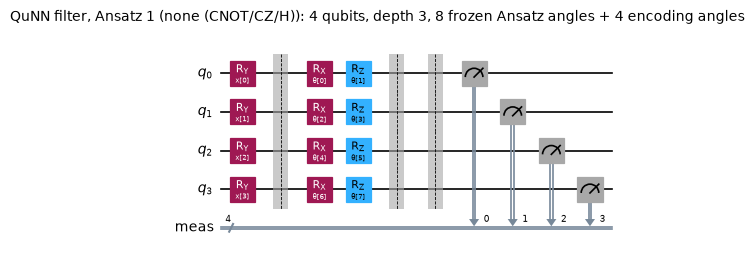

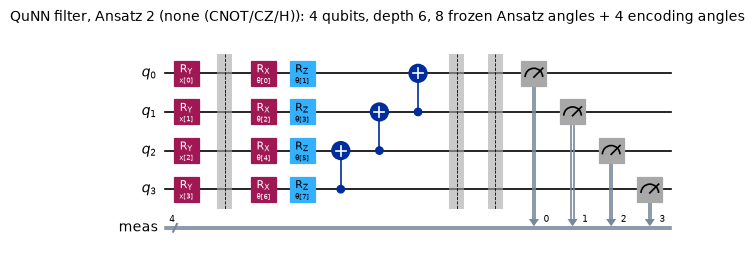

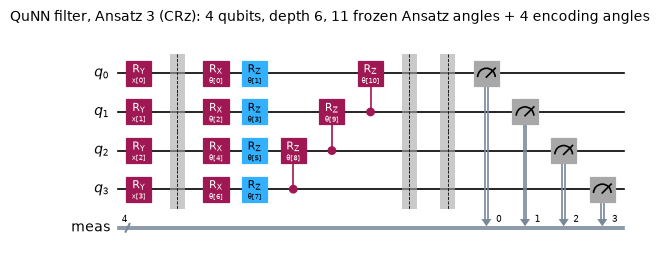

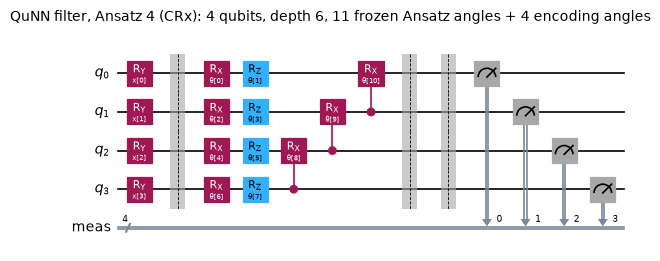

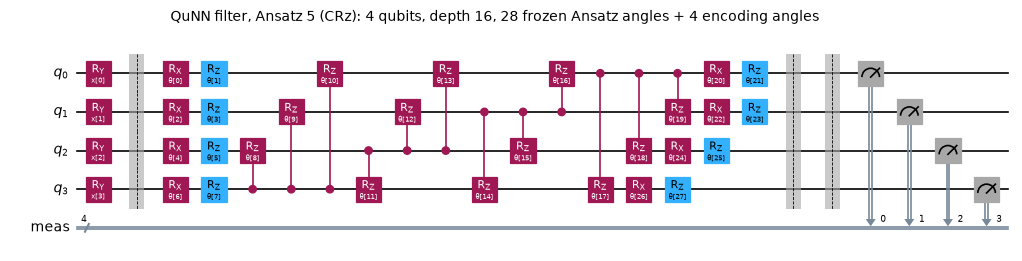

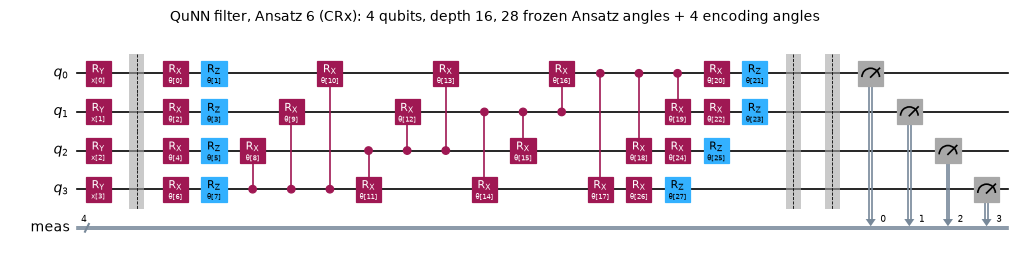

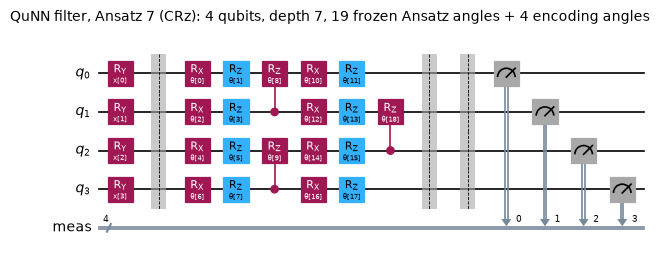

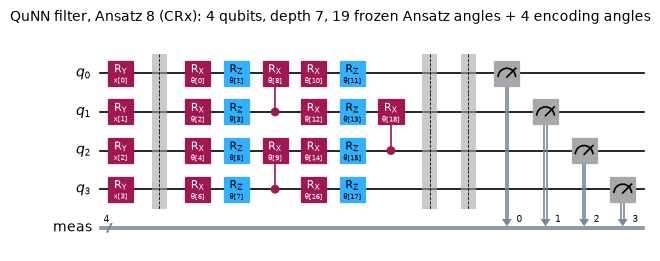

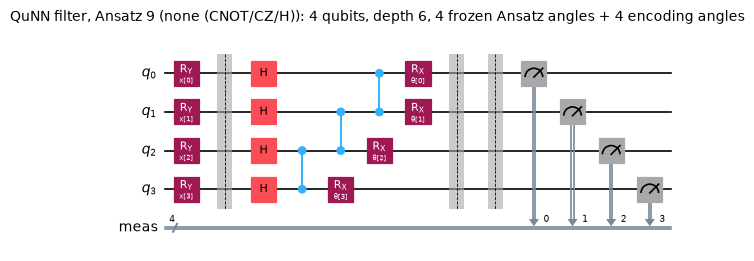

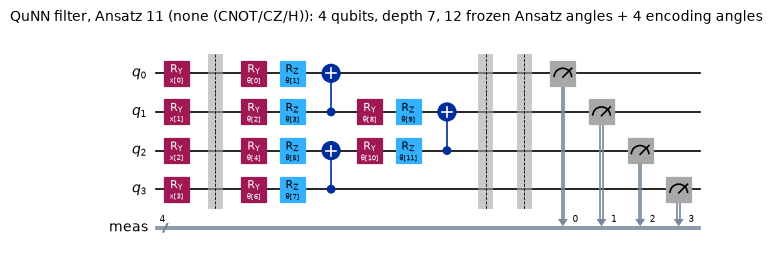

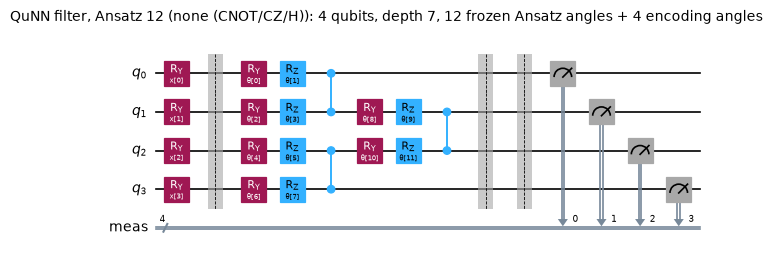

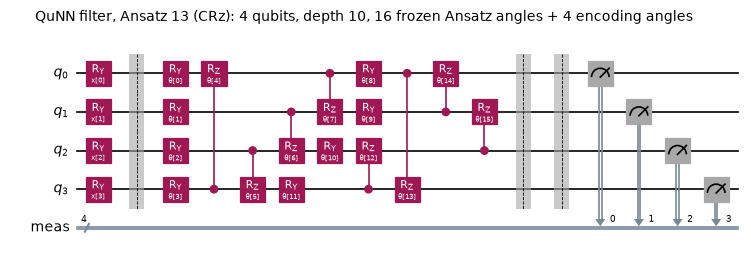

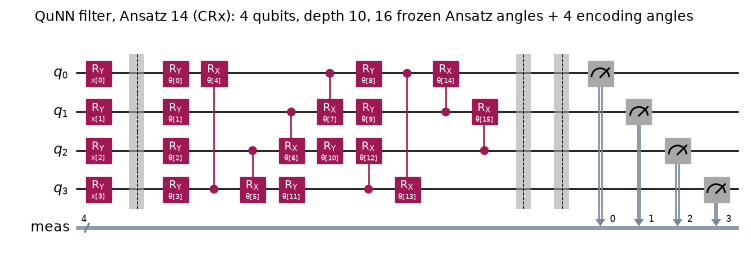

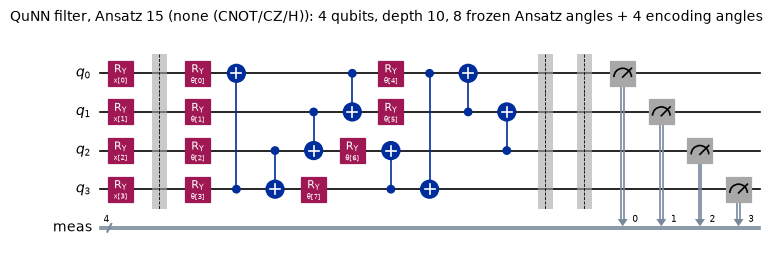

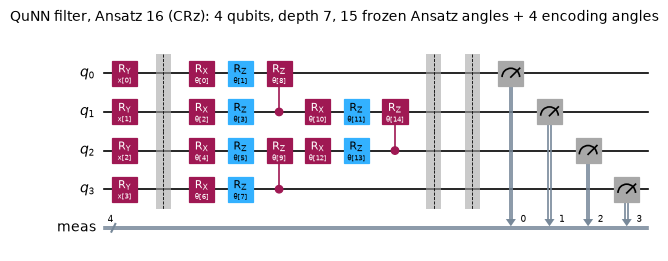

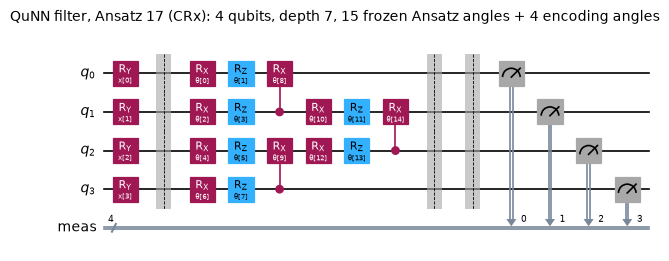

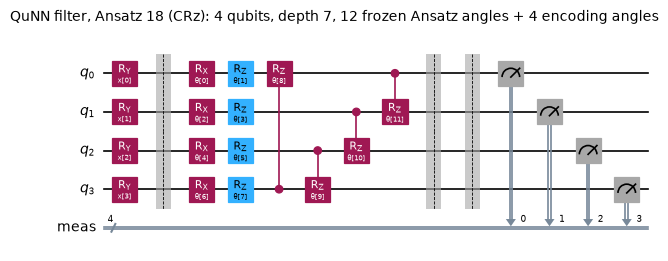

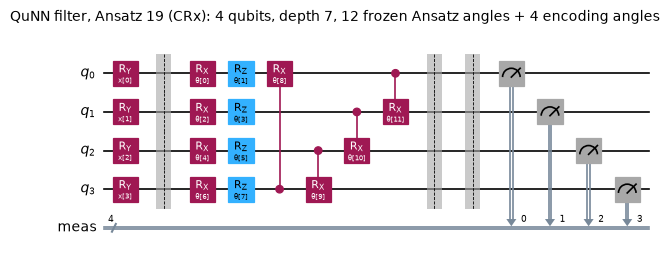

In [11]:
# draw every distinct architecture that is trained or evaluated (the circuit object that is actually executed: encoding, Ansatz, read-out)
for k in ALL_ANSATZ:
    qc = build_qiskit(k)
    fig = qc.draw("mpl", fold=-1, scale=0.6)
    fig.suptitle(f"QuNN filter, Ansatz {k} ({ctrl_type(k)}): 4 qubits, depth {build_qiskit(k, measure=False).depth()}, {n_params(ansatz_ops(k))} frozen Ansatz angles + 4 encoding angles", fontsize=10, y=1.0)
    display(fig); plt.close(fig)

## 4. Circuit metrics: expressibility and entangling capability (paper Table 1)

* **Expressibility** (Sim et al.): draw `N_PAIRS` pairs of random parameter vectors (uniform in [0, 2 pi)), compute the fidelity `F = |<psi(a)|psi(b)>|^2` of the two output states, histogram `F` into 75 bins to get `P_A(F)`, and compute
  `KL(P_A || P_Haar)` with the exact Haar bin masses `(1-F_lo)^(N-1) - (1-F_hi)^(N-1)`, `N = 2^4 = 16`. **Lower is more expressive.**
* **Entangling capability**: the mean Meyer-Wallach measure `Q = 2 (1 - (1/n) sum_i Tr rho_i^2)` of the same kind of random output states. **Higher is more entangling** (0 = product states, 1 = e.g. GHZ).

The same functions are applied to the circuits of this notebook and compared with the numbers the paper prints in Table 1.

In [12]:
def random_states(ops, B, rng):
    th = rng.uniform(0, 2 * np.pi, (B, n_params(ops)))
    return run_ops(ops, th, zero_state(B)).reshape(B, 16)

def expressibility(ops, rng, n_pairs=N_PAIRS, bins=N_BINS):
    a = random_states(ops, n_pairs, rng); b = random_states(ops, n_pairs, rng)
    F = np.abs(np.sum(np.conj(a) * b, axis=1)) ** 2
    edges = np.linspace(0, 1, bins + 1); P = np.histogram(F, bins=edges)[0] / n_pairs
    Q = (1 - edges[:-1]) ** 15 - (1 - edges[1:]) ** 15                       # Haar bin masses for N = 16
    m = P > 0
    return float(np.sum(P[m] * np.log(P[m] / Q[m])))

def meyer_wallach(psi):
    B = psi.shape[0]; t = psi.reshape(B, 2, 2, 2, 2); pur = []
    for i in range(4):
        m = np.moveaxis(t, i + 1, 1).reshape(B, 2, 8)
        rho = np.einsum("bik,bjk->bij", m, np.conj(m)); pur.append(np.real(np.einsum("bij,bji->b", rho, rho)))
    return 2 * (1 - np.mean(pur, axis=0))

def entangling_capability(ops, rng, n=N_PAIRS): return float(np.mean(meyer_wallach(random_states(ops, n, rng))))

# sanity: a GHZ state has Q = 1, a product state Q = 0
_g = np.zeros((1, 16), complex); _g[0, 0] = _g[0, 15] = 1 / math.sqrt(2); _p = np.zeros((1, 16), complex); _p[0, 5] = 1
assert abs(meyer_wallach(_g)[0] - 1) < 1e-12 and abs(meyer_wallach(_p)[0]) < 1e-12

PAPER_T1 = {1: (0.4015, 0.0), 2: (0.3028, 0.6130), 3: (0.2536, 0.1767), 4: (0.0987, 0.3016), 5: (0.0755, 0.2833), 6: (0.0105, 0.6800), 7: (0.1305, 0.1995), 8: (0.0835, 0.2856),
            9: (0.6946, 1.0), 11: (0.1339, 0.5336), 12: (0.2247, 0.3999), 13: (0.0956, 0.4078), 14: (0.0496, 0.5403), 15: (0.1915, 0.7094), 16: (0.3083, 0.1723), 17: (0.1665, 0.2912),
            18: (0.2495, 0.2100), 19: (0.0933, 0.3958)}
PAPER_CTRL = {1: "-", 2: "-", 3: "CRz", 4: "CRx", 5: "CRz", 6: "CRx", 7: "CRz", 8: "CRx", 9: "-", 11: "CRz*", 12: "CRx*", 13: "CRz", 14: "CRx", 15: "-", 16: "CRz", 17: "CRx", 18: "CRz", 19: "CRx"}

t0 = time.time(); r_m = np.random.default_rng(SEED + 99); rows = []
for k in ALL_ANSATZ:
    ops = ansatz_ops(k)
    rows.append({"Ansatz": k, "controlled gate (paper)": PAPER_CTRL[k], "Expr. paper": PAPER_T1[k][0], "Expr. here": expressibility(ops, r_m), "Ent. paper": PAPER_T1[k][1], "Ent. here": entangling_capability(ops, r_m)})
T1 = pd.DataFrame(rows).set_index("Ansatz"); T1["dExpr"] = T1["Expr. here"] - T1["Expr. paper"]; T1["dEnt"] = T1["Ent. here"] - T1["Ent. paper"]
display(T1.round(4)); print(f"computed in {time.time() - t0:.0f} s with {N_PAIRS} random parameter draws per circuit.  (*) the paper labels Ansatz 11/12 as CRz/CRx; in Sim et al. they are the CNOT / CZ circuits.")
print(f"entangling capability: max |diff| = {T1['dEnt'].abs().max():.3f}, mean |diff| = {T1['dEnt'].abs().mean():.3f};   expressibility: max |diff| = {T1['dExpr'].abs().max():.3f}, mean |diff| = {T1['dExpr'].abs().mean():.3f}")
print("rank correlation (Spearman) with the paper: expressibility", round(spearmanr(T1["Expr. here"], T1["Expr. paper"])[0], 3), " entangling capability", round(spearmanr(T1["Ent. here"], T1["Ent. paper"])[0], 3))

,controlled gate (paper),Expr. paper,Expr. here,Ent. paper,Ent. here,dExpr,dEnt
Ansatz,,,,,,,
1,-,0.4015,0.3071,0.0000,0.0000,-0.0944,0.0000
2,-,0.3028,0.2895,0.6130,0.6222,-0.0133,0.0092
3,CRz,0.2536,0.2585,0.1767,0.1725,0.0049,-0.0042
4,CRx,0.0987,0.1329,0.3016,0.3113,0.0342,0.0097
5,CRz,0.0755,0.0521,0.2833,0.2909,-0.0234,0.0076
6,CRx,0.0105,0.0025,0.6800,0.6842,-0.0080,0.0042
7,CRz,0.1305,0.1093,0.1995,0.2103,-0.0212,0.0108
8,CRx,0.0835,0.0746,0.2856,0.2914,-0.0089,0.0058
9,-,0.6946,0.6486,1.0000,1.0000,-0.0460,0.0000


computed in 50 s with 20000 random parameter draws per circuit.  (*) the paper labels Ansatz 11/12 as CRz/CRx; in Sim et al. they are the CNOT / CZ circuits.
entangling capability: max |diff| = 0.040, mean |diff| = 0.007;   expressibility: max |diff| = 0.146, mean |diff| = 0.034
rank correlation (Spearman) with the paper: expressibility 0.944  entangling capability 0.988


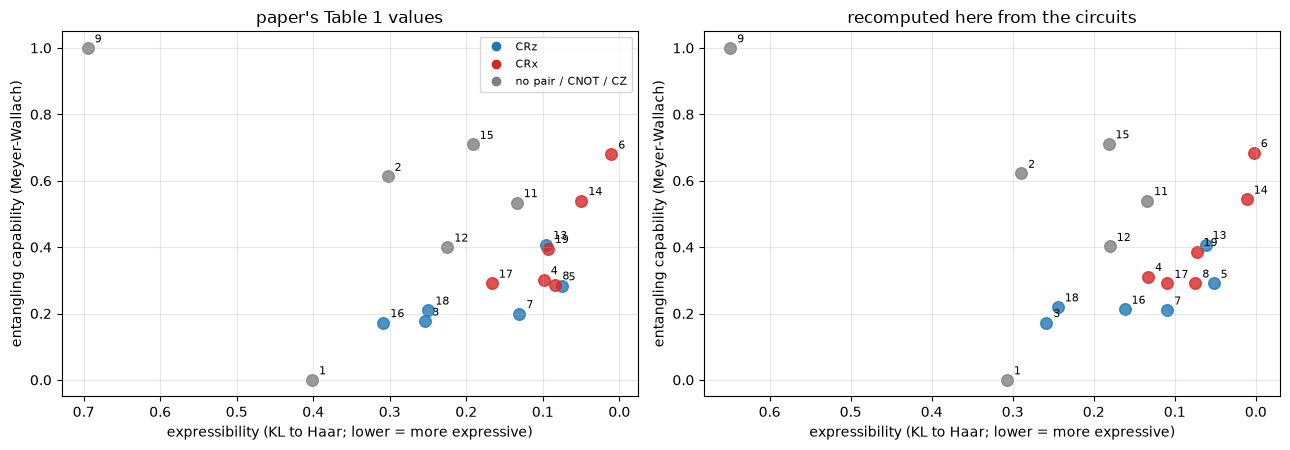

In [13]:
# paper Fig. 11: expressibility vs entangling capability, coloured by controlled-rotation type
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
colors = {"CRz": "tab:blue", "CRx": "tab:red", "-": "tab:gray", "CRz*": "tab:gray", "CRx*": "tab:gray"}
for ax, (xc, yc, ttl) in zip(axes, [("Expr. paper", "Ent. paper", "paper's Table 1 values"), ("Expr. here", "Ent. here", "recomputed here from the circuits")]):
    for k, r_ in T1.iterrows():
        ax.scatter(r_[xc], r_[yc], s=70, color=colors[r_["controlled gate (paper)"]], alpha=0.8); ax.annotate(str(k), (r_[xc], r_[yc]), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.set_xlabel("expressibility (KL to Haar; lower = more expressive)"); ax.set_ylabel("entangling capability (Meyer-Wallach)"); ax.set_title(ttl)
    ax.invert_xaxis()
from matplotlib.lines import Line2D
axes[0].legend(handles=[Line2D([0], [0], marker="o", ls="", color=c, label=l) for l, c in [("CRz", "tab:blue"), ("CRx", "tab:red"), ("no pair / CNOT / CZ", "tab:gray")]], fontsize=8)
plt.tight_layout(); plt.show()

## 5. Train every model, attack it, repeat over seeds

For every dataset, run (seed) and model (the CNN and one QuNN per circuit) the loop below

1. draws the frozen convolution (random Ansatz angles uniform in [0, 2 pi), or a Glorot-uniform `Conv2D` kernel),
2. computes the 784 convolution features of the 1000 training images and trains the dense head (Adam, batch 4, `EPOCHS` epochs),
3. measures the clean accuracy on the test images, the FGSM accuracy for every epsilon in `FGSM_EPS` (one gradient, then `x + eps sign(g)`), and the PGD accuracy for every epsilon in `PGD_EPS`,
4. measures the **average gradient magnitude** (AGM) of the loss with respect to the clean test images (paper Table 3): the mean absolute pixel gradient and the mean L2 norm of the image gradient.

All models of one run share the head-initialisation and shuffling stream, so differences between circuits come from the circuit only. A progress line is printed per dataset and seed.

In [14]:
MODELS = ["CNN"] + [f"A{k}" for k in ATTACK_ANSATZ]
RES = {}          # RES[(dataset, model)] = {"fgsm": [per seed], "pgd": [...], "agm_l1": [...], "agm_l2": [...], "train_acc": [...]}
T_START = time.time()
import pickle, gc
CKPT_DIR = os.path.join(DATA_DIR, "ckpt"); os.makedirs(CKPT_DIR, exist_ok=True)
CFG_TAG = f"{'fast' if FAST_MODE else 'full'}_s{SEED}_tr{N_TRAIN}_te{N_TEST}_ep{EPOCHS}_pgd{PGD_ITERS}_f{len(FGSM_EPS)}p{len(PGD_EPS)}_a{'-'.join(map(str, ATTACK_ANSATZ))}"

def make_layer(model, ds_i, seed):
    ss = np.random.SeedSequence([SEED, seed, ds_i, 0 if model == "CNN" else int(model[1:])])
    r = np.random.default_rng(ss)
    if model == "CNN": return Conv(r)
    ops = ansatz_ops(int(model[1:])); return Quanv(ops, r.uniform(0, 2 * np.pi, n_params(ops)))      # CHOICE: random frozen Ansatz angles

def run_one(model, ds, ds_i, seed):
    D = DATA[ds]; layer = make_layer(model, ds_i, seed)
    r_head = np.random.default_rng(np.random.SeedSequence([SEED, seed, ds_i, 12345]))
    Ftr = layer.forward(D["Xtr"]); W, b = train_head(Ftr, D["ytr"], r_head, EPOCHS)
    m = Model(layer, W, b); X, y = D["Xte"], D["yte"]
    g = m.grad(X, y); sg = np.sign(g)
    f_acc = [m.acc(np.clip(X + e * sg, 0, 1), y) if e > 0 else m.acc(X, y) for e in FGSM_EPS]           # FGSM: one gradient, all epsilons
    p_acc = [m.acc(pgd(m, X, y, e, PGD_ITERS), y) if e > 0 else m.acc(X, y) for e in PGD_EPS]
    return dict(fgsm=f_acc, pgd=p_acc, agm_l1=float(np.abs(g).mean()), agm_l2=float(np.sqrt((g ** 2).sum((1, 2))).mean()), train_acc=m.acc(D["Xtr"], D["ytr"]))

for ds_i, ds in enumerate(DATASETS):
    for seed in range(N_SEEDS):
        t_s = time.time(); ck = os.path.join(CKPT_DIR, f"{CFG_TAG}_{ds}_{seed}.pkl")
        if os.path.exists(ck):                                              # resume after an interrupted session (Colab disconnects)
            recs = pickle.load(open(ck, "rb")); how = "loaded from checkpoint"
        else:
            recs = {}
            for model in MODELS:
                for attempt in range(6):                                    # a shared / small-memory machine can raise a transient MemoryError: wait and retry
                    try: recs[model] = run_one(model, ds, ds_i, seed); break
                    except MemoryError:
                        gc.collect(); time.sleep(30)
                else: raise MemoryError("out of memory after 6 attempts")
            pickle.dump(recs, open(ck, "wb")); how = f"computed in {time.time() - t_s:5.0f} s"
        for model in MODELS:
            R = RES.setdefault((ds, model), {"fgsm": [], "pgd": [], "agm_l1": [], "agm_l2": [], "train_acc": []})
            for key in R: R[key].append(recs[model][key])
        print(f"{FULL_NAME[ds]:>13} seed {seed + 1}/{N_SEEDS} {how}  (elapsed {(time.time() - T_START) / 60:.1f} min)   "
              f"clean test acc CNN {recs['CNN']['fgsm'][0]:.2f}" + "".join(f", A{k} {recs[f'A{k}']['fgsm'][0]:.2f}" for k in ATTACK_ANSATZ[:3]))
for R in RES.values():
    for key in ("fgsm", "pgd"): R[key] = np.array(R[key])
print(f"total {(time.time() - T_START) / 60:.1f} min")

        MNIST seed 1/5 computed in   458 s  (elapsed 7.6 min)   clean test acc CNN 0.87, A1 0.83, A2 0.87, A3 0.82


        MNIST seed 2/5 computed in   441 s  (elapsed 15.0 min)   clean test acc CNN 0.87, A1 0.75, A2 0.86, A3 0.73


        MNIST seed 3/5 computed in   422 s  (elapsed 22.0 min)   clean test acc CNN 0.91, A1 0.80, A2 0.79, A3 0.78


        MNIST seed 4/5 computed in   500 s  (elapsed 30.3 min)   clean test acc CNN 0.87, A1 0.83, A2 0.85, A3 0.81


        MNIST seed 5/5 computed in   443 s  (elapsed 37.7 min)   clean test acc CNN 0.83, A1 0.79, A2 0.85, A3 0.81


Fashion-MNIST seed 1/5 computed in   459 s  (elapsed 45.4 min)   clean test acc CNN 0.79, A1 0.63, A2 0.68, A3 0.63


Fashion-MNIST seed 2/5 computed in   474 s  (elapsed 53.3 min)   clean test acc CNN 0.79, A1 0.66, A2 0.72, A3 0.63


Fashion-MNIST seed 3/5 computed in   483 s  (elapsed 61.3 min)   clean test acc CNN 0.81, A1 0.61, A2 0.69, A3 0.63


Fashion-MNIST seed 4/5 computed in   540 s  (elapsed 70.3 min)   clean test acc CNN 0.77, A1 0.62, A2 0.71, A3 0.61


Fashion-MNIST seed 5/5 computed in   639 s  (elapsed 81.0 min)   clean test acc CNN 0.77, A1 0.67, A2 0.67, A3 0.67
total 81.0 min


In [15]:
# clean accuracy (eps = 0) and training accuracy, mean +- std over seeds
rows = []
for model in MODELS:
    row = {"model": model if model == "CNN" else f"QuNN {model}"}
    for ds in DATASETS:
        R = RES[(ds, model)]
        row[f"{ds} train acc"] = f"{np.mean(R['train_acc']):.3f}"
        row[f"{ds} clean test acc"] = f"{R['fgsm'][:, 0].mean():.3f} +- {R['fgsm'][:, 0].std():.3f}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))

,MNIST train acc,MNIST clean test acc,FMNIST train acc,FMNIST clean test acc
model,,,,
CNN,0.980,0.868 +- 0.023,0.930,0.787 +- 0.015
QuNN A1,0.842,0.799 +- 0.027,0.701,0.637 +- 0.022
QuNN A2,0.891,0.844 +- 0.026,0.757,0.695 +- 0.019
QuNN A3,0.831,0.791 +- 0.032,0.710,0.635 +- 0.018
QuNN A4,0.901,0.828 +- 0.009,0.775,0.693 +- 0.041
QuNN A5,0.906,0.851 +- 0.030,0.743,0.672 +- 0.041
QuNN A6,0.931,0.865 +- 0.010,0.846,0.736 +- 0.018
QuNN A7,0.930,0.855 +- 0.023,0.854,0.743 +- 0.042
QuNN A8,0.932,0.849 +- 0.020,0.849,0.747 +- 0.030


### 5.1 Figures of the paper, redrawn

Each figure has the paper's four panels: (a) MNIST FGSM, (b) Fashion-MNIST FGSM, (c) MNIST PGD, (d) Fashion-MNIST PGD; accuracy against perturbation strength epsilon, mean over seeds with
standard-deviation error bars. The classical CNN (dashed black) is added to every panel (the paper shows it in Fig. 5). Epsilon ranges follow the paper: FGSM 0-1, PGD 0-0.1.

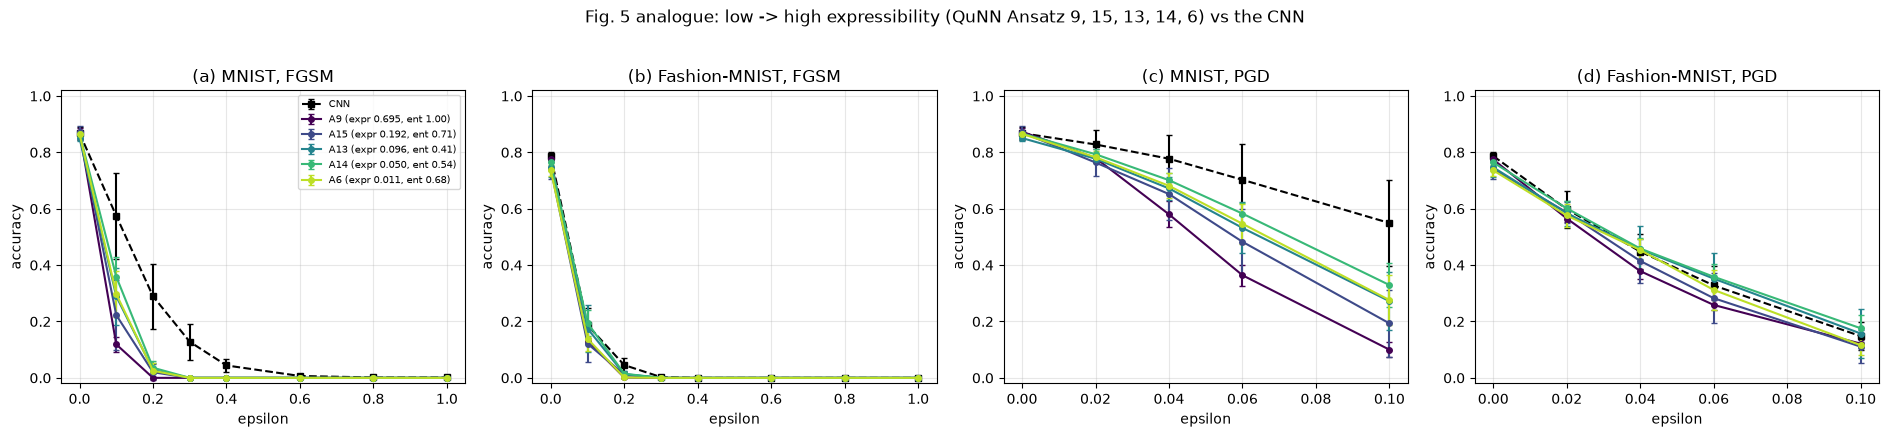

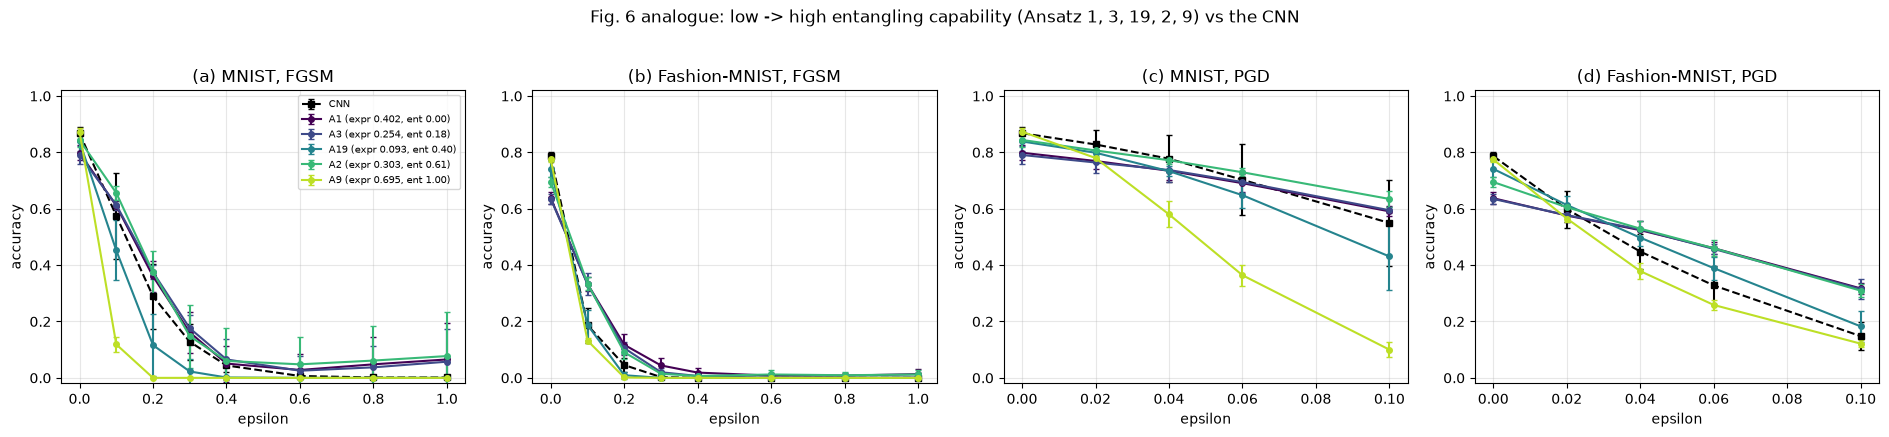

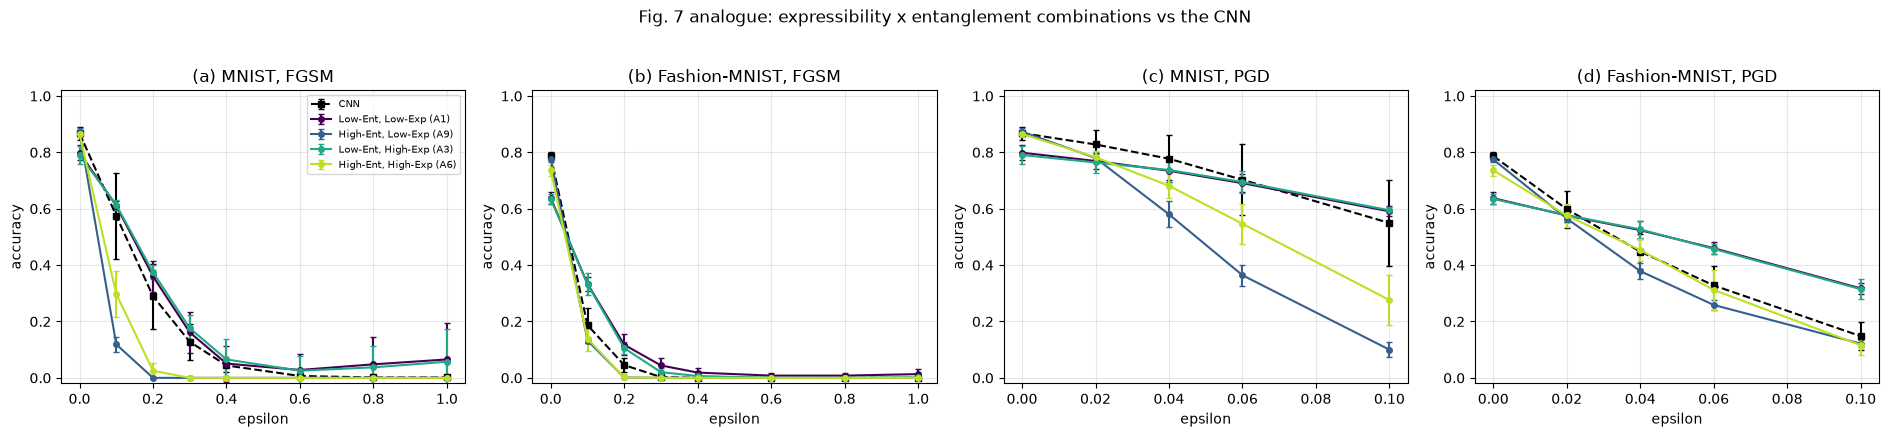

In [16]:
def curve(ds, atk, model):
    a = RES[(ds, model)][atk]; return a.mean(0), a.std(0)

def plot_group(title, members, with_cnn=True):
    # members: list of (label, model-key)
    members = [(l, k) for l, k in members if (DATASETS[0], k) in RES]
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
    panels = [("MNIST", "fgsm", "(a) MNIST, FGSM"), ("FMNIST", "fgsm", "(b) Fashion-MNIST, FGSM"), ("MNIST", "pgd", "(c) MNIST, PGD"), ("FMNIST", "pgd", "(d) Fashion-MNIST, PGD")]
    cm = plt.get_cmap("viridis")
    for ax, (ds, atk, ttl) in zip(axes, panels):
        eps = FGSM_EPS if atk == "fgsm" else PGD_EPS
        if with_cnn:
            mu, sd = curve(ds, atk, "CNN"); ax.errorbar(eps, mu, sd, color="k", ls="--", marker="s", ms=4, capsize=2, label="CNN")
        for i, (lab, key) in enumerate(members):
            mu, sd = curve(ds, atk, key); ax.errorbar(eps, mu, sd, color=cm(i / max(1, len(members) - 1) * 0.9), marker="o", ms=4, capsize=2, label=lab)
        ax.set_xlabel("epsilon"); ax.set_ylabel("accuracy"); ax.set_title(ttl); ax.set_ylim(-0.02, 1.02)
    axes[0].legend(fontsize=7)
    fig.suptitle(title, y=1.03); plt.tight_layout(); plt.show()

EXPR_GROUP = [9, 15, 13, 14, 6]     # low -> high expressibility (paper Table 2)
ENT_GROUP  = [1, 3, 19, 2, 9]       # low -> high entangling capability
COMBO      = [("Low-Ent, Low-Exp (A1)", 1), ("High-Ent, Low-Exp (A9)", 9), ("Low-Ent, High-Exp (A3)", 3), ("High-Ent, High-Exp (A6)", 6)]
PAIRS      = [(3, 4), (5, 6), (7, 8), (13, 14), (16, 17), (18, 19)]      # (CRz circuit, CRx circuit)
lab = lambda k: f"A{k} (expr {PAPER_T1[k][0]:.3f}, ent {PAPER_T1[k][1]:.2f})"

plot_group("Fig. 5 analogue: low -> high expressibility (QuNN Ansatz 9, 15, 13, 14, 6) vs the CNN", [(lab(k), f"A{k}") for k in EXPR_GROUP])
plot_group("Fig. 6 analogue: low -> high entangling capability (Ansatz 1, 3, 19, 2, 9) vs the CNN", [(lab(k), f"A{k}") for k in ENT_GROUP])
plot_group("Fig. 7 analogue: expressibility x entanglement combinations vs the CNN", [(l, f"A{k}") for l, k in COMBO])

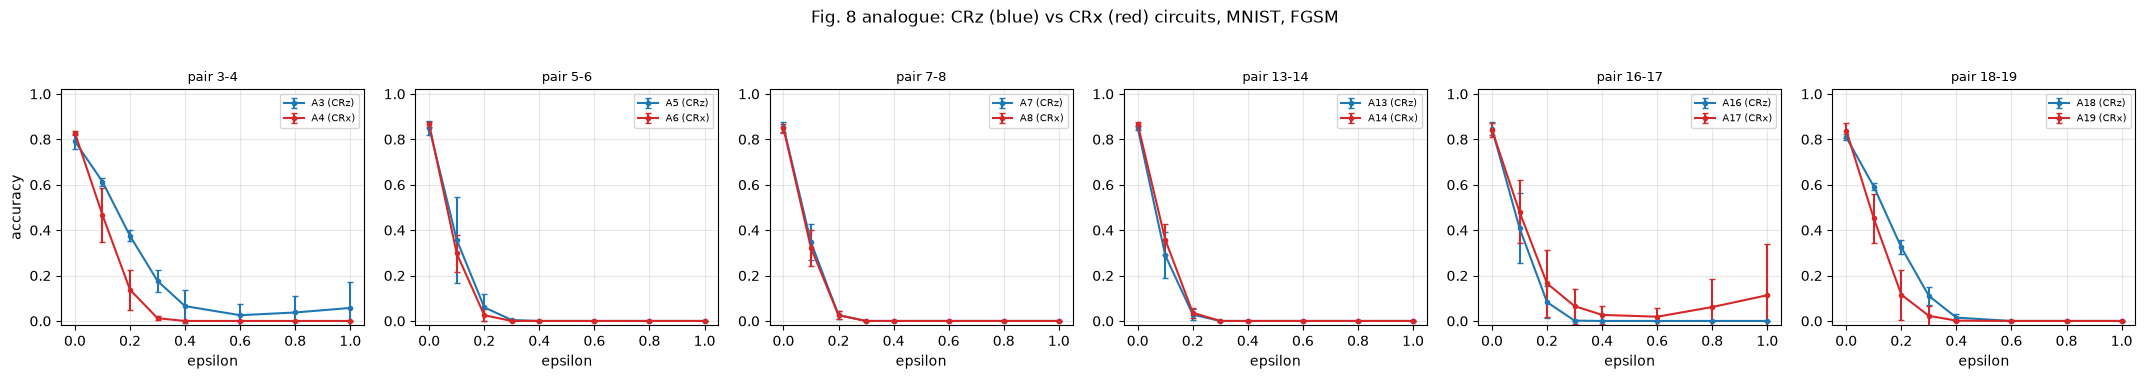

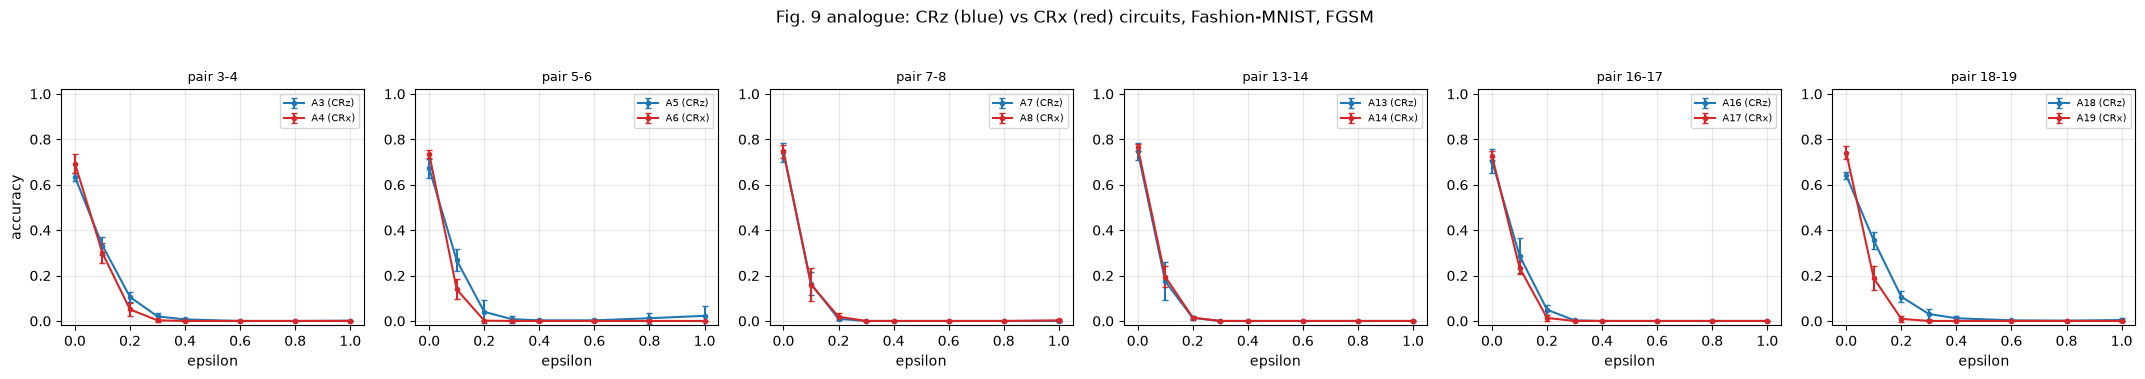

In [17]:
# Fig. 8 / 9 analogue: CRz vs CRx partners under FGSM
avail_pairs = [(a, b) for a, b in PAIRS if ("MNIST", f"A{a}") in RES and ("MNIST", f"A{b}") in RES]
if not avail_pairs:
    print("The CRz/CRx pairs are not part of the FAST_MODE circuit subset; set FAST_MODE = False to run them.")
else:
    for ds in DATASETS:
        fig, axes = plt.subplots(1, len(avail_pairs), figsize=(3.6 * len(avail_pairs), 3.6), squeeze=False)
        for ax, (a, b) in zip(axes[0], avail_pairs):
            for k, col in ((a, "tab:blue"), (b, "tab:red")):
                mu, sd = curve(ds, "fgsm", f"A{k}"); ax.errorbar(FGSM_EPS, mu, sd, color=col, marker="o", ms=3, capsize=2, label=f"A{k} ({ctrl_type(k)})")
            ax.set_title(f"pair {a}-{b}", fontsize=9); ax.set_xlabel("epsilon"); ax.set_ylim(-0.02, 1.02); ax.legend(fontsize=7)
        axes[0, 0].set_ylabel("accuracy")
        fig.suptitle(f"Fig. {8 if ds == 'MNIST' else 9} analogue: CRz (blue) vs CRx (red) circuits, {FULL_NAME[ds]}, FGSM", y=1.04); plt.tight_layout(); plt.show()

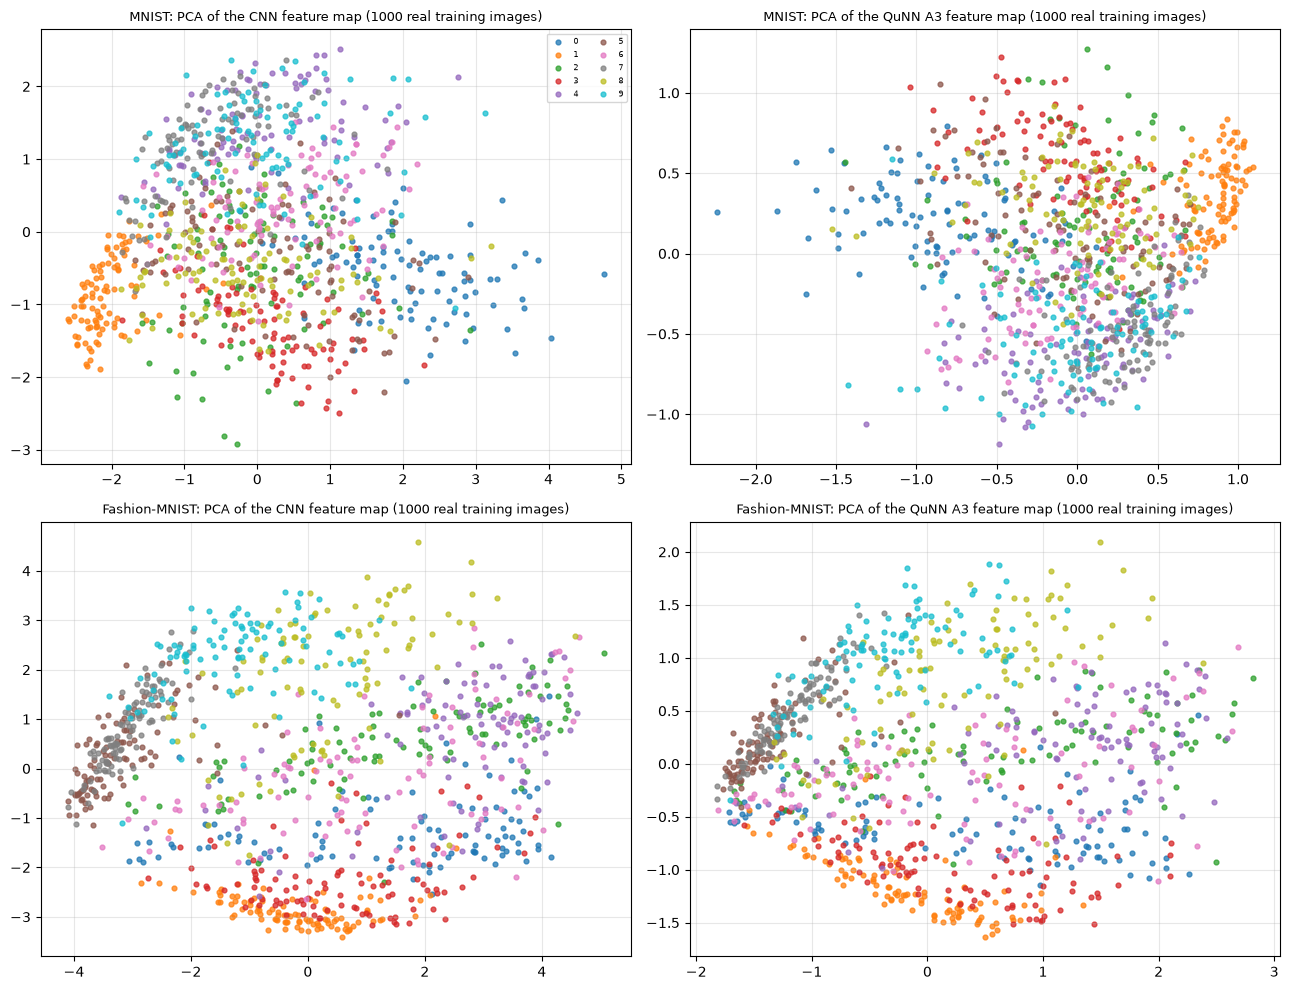

In [18]:
# quantum feature space of real data: PCA of the 784 quanvolution features of the training images, coloured by ground-truth label (frozen filter of seed 0)
demo = "A3" if "A3" in MODELS else MODELS[1]
fig, axes = plt.subplots(2, 2, figsize=(13, 10)); cmap = plt.get_cmap("tab10")
for r_, ds in enumerate(DATASETS):
    D = DATA[ds]
    for c_, model in enumerate(["CNN", demo]):
        layer = make_layer(model, r_, 0); F = layer.forward(D["Xtr"]); Z = PCA(n_components=2, random_state=SEED).fit(F).transform(F)
        for c in range(10):
            mk = D["ytr"] == c; axes[r_, c_].scatter(Z[mk, 0], Z[mk, 1], s=12, color=cmap(c), alpha=0.75, label=CLASS_NAMES[ds][c])
        axes[r_, c_].set_title(f"{FULL_NAME[ds]}: PCA of the {'CNN' if model == 'CNN' else 'QuNN ' + model} feature map (1000 real training images)", fontsize=9)
axes[0, 0].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()

## 6. Average gradient magnitude (paper Table 3)

The paper explains the robustness differences with the average gradient magnitude (AGM) of the loss with respect to the input (Table 3, MNIST). It does not define the exact norm; two natural readings are computed:
the mean absolute pixel gradient (`L1/pixel`) and the mean per-image L2 norm of the gradient (`L2`). Gradients are those of the per-sample cross-entropy at the clean test images.

,AGM L1/pixel (mean+-std),AGM L2 per image (mean+-std),paper Table 3
model,,,
CNN,0.0097 +- 0.0043,0.799 +- 0.395,1.7965
A1,0.0062 +- 0.0003,0.607 +- 0.022,0.8249
A2,0.0055 +- 0.0005,0.591 +- 0.022,NaN
A3,0.0059 +- 0.0003,0.596 +- 0.029,0.7650
A4,0.0126 +- 0.0039,0.753 +- 0.156,NaN
A5,0.0160 +- 0.0056,0.876 +- 0.207,NaN
A6,0.0173 +- 0.0033,0.967 +- 0.252,1.5437
A7,0.0163 +- 0.0026,0.949 +- 0.229,NaN
A8,0.0179 +- 0.0032,0.924 +- 0.162,NaN


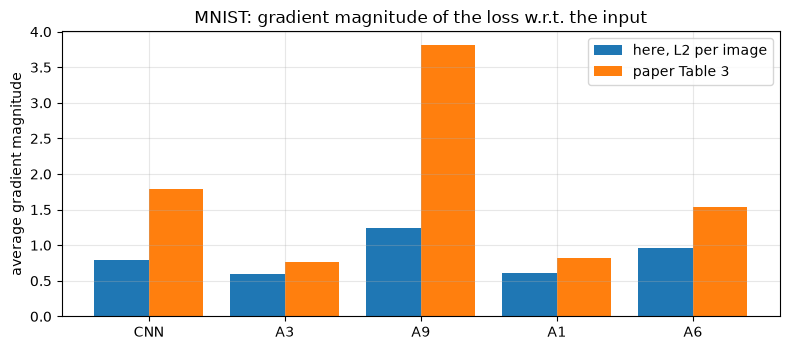

In [19]:
PAPER_AGM = {"CNN": 1.7965, "A3": 0.7650, "A9": 3.8145, "A1": 0.8249, "A6": 1.5437}
rows = []
for model in MODELS:
    R = RES[("MNIST", model)]
    rows.append({"model": model, "AGM L1/pixel (mean+-std)": f"{np.mean(R['agm_l1']):.4f} +- {np.std(R['agm_l1']):.4f}", "AGM L2 per image (mean+-std)": f"{np.mean(R['agm_l2']):.3f} +- {np.std(R['agm_l2']):.3f}",
                 "paper Table 3": PAPER_AGM.get(model, np.nan), "_l1": np.mean(R["agm_l1"]), "_l2": np.mean(R["agm_l2"])})
AGM = pd.DataFrame(rows).set_index("model"); display(AGM.drop(columns=["_l1", "_l2"]))
fig, ax = plt.subplots(figsize=(8, 3.6)); ks = [k for k in PAPER_AGM if k in AGM.index]
ax.bar(np.arange(len(ks)) - 0.2, [AGM.loc[k, "_l2"] for k in ks], 0.4, label="here, L2 per image"); ax.bar(np.arange(len(ks)) + 0.2, [PAPER_AGM[k] for k in ks], 0.4, label="paper Table 3")
ax.set_xticks(range(len(ks))); ax.set_xticklabels(ks); ax.set_ylabel("average gradient magnitude"); ax.legend(); ax.set_title("MNIST: gradient magnitude of the loss w.r.t. the input"); plt.tight_layout(); plt.show()

## 7. Side-by-side comparison with the paper, claim by claim

*Robustness score* of a model on one panel = mean accuracy over the non-zero epsilons of an attack, averaged over seeds ("low" = FGSM epsilon <= 0.4 or PGD epsilon <= 0.04, as defined in the paper; "all" = every non-zero epsilon).
The verdict rules are written next to each claim so that they can be challenged: **reproduced** when the rule is satisfied, **not reached** / **exceeded** when a number falls short of / goes beyond the paper, **cannot be checked** when the
needed circuits were not run (FAST_MODE subset) or the paper gives no number.

In [20]:
def score(ds, atk, model, region="all"):
    eps = np.array(FGSM_EPS if atk == "fgsm" else PGD_EPS); a = RES[(ds, model)][atk].mean(0)
    sel = (eps > 0) & ((eps <= (0.4 if atk == "fgsm" else 0.04) + 1e-9) if region == "low" else True)
    return float(a[sel].mean())

PANELS = [("MNIST", "fgsm"), ("FMNIST", "fgsm"), ("MNIST", "pgd"), ("FMNIST", "pgd")]
have = lambda ks: all(("MNIST", f"A{k}") in RES for k in ks)
V = []        # (claim, paper, here, verdict, rule)

# C1/C2: Table 1 metrics
n_e = int((T1["dExpr"].abs() <= 0.05).sum()); n_q = int((T1["dEnt"].abs() <= 0.02).sum())
rho_e = spearmanr(T1["Expr. here"], T1["Expr. paper"])[0]; rho_q = spearmanr(T1["Ent. here"], T1["Ent. paper"])[0]
V.append(("Table 1: expressibility of the 18 circuits", "values 0.0105 - 0.6946", f"{n_e}/18 within 0.05, mean |diff| {T1['dExpr'].abs().mean():.3f}, Spearman {rho_e:.2f}", "reproduced" if n_e >= 16 and rho_e >= 0.9 else "not reached", ">= 16/18 within 0.05 and rank correlation >= 0.9"))
V.append(("Table 1: entangling capability of the 18 circuits", "values 0 - 1", f"{n_q}/18 within 0.02, mean |diff| {T1['dEnt'].abs().mean():.3f}, Spearman {rho_q:.2f}", "reproduced" if n_q >= 16 and rho_q >= 0.9 else "not reached", ">= 16/18 within 0.02 and rank correlation >= 0.9"))

# C3: QuNN vs CNN
wins = tot = 0; best = {}
for ds, atk in PANELS:
    for k in ATTACK_ANSATZ:
        wins += score(ds, atk, f"A{k}") > score(ds, atk, "CNN"); tot += 1
for ds in DATASETS:
    gaps = [(RES[(ds, f"A{k}")]["fgsm"].mean(0) - RES[(ds, "CNN")]["fgsm"].mean(0)).max() * 100 for k in ATTACK_ANSATZ]; best[ds] = max(gaps)
V.append(("QuNNs beat the CNN under attack", "'consistently outperformed' (Fig. 5)", f"{wins}/{tot} (circuit, panel) pairs have a higher mean accuracy than the CNN", "reproduced" if wins / tot >= 0.75 else "not reached", ">= 75 % of (circuit, panel) pairs above the CNN (mean accuracy over all non-zero epsilons)"))
for ds, claim in (("MNIST", 60), ("FMNIST", 40)):
    v = "reproduced" if abs(best[ds] - claim) <= 10 else ("exceeded" if best[ds] > claim else "not reached")
    V.append((f"Largest FGSM accuracy gain of a QuNN over the CNN, {FULL_NAME[ds]}", f"'up to {claim} %'", f"{best[ds]:.1f} percentage points (best circuit, best epsilon)", v, "within 10 points of the paper's figure (reading '% greater robustness' as accuracy points)"))

# C4: expressibility -> robustness
if have(EXPR_GROUP):
    rr = []; ok = 0
    for ds, atk in PANELS:
        rho = spearmanr([PAPER_T1[k][0] for k in EXPR_GROUP], [score(ds, atk, f"A{k}", "low") for k in EXPR_GROUP])[0]; rr.append(rho); ok += rho <= -0.5
    V.append(("Higher expressibility -> higher robustness at low epsilon", "monotone trend, groups 9, 15, 13, 14, 6 (A13 > A14 noted as exception)", "Spearman(KL, score) per panel: " + ", ".join(f"{x:+.2f}" for x in rr), "reproduced" if ok >= 3 else "not reached", "negative rank correlation <= -0.5 (KL down = expressibility up) in >= 3 of 4 panels, 5 circuits per panel"))
else:
    V.append(("Higher expressibility -> higher robustness at low epsilon", "monotone trend", "circuits not run in FAST_MODE subset", "cannot be checked", ""))
# C5: entanglement -> robustness
if have(ENT_GROUP):
    rr = []; ok = 0
    for ds, atk in PANELS:
        rho = spearmanr([PAPER_T1[k][1] for k in ENT_GROUP], [score(ds, atk, f"A{k}", "all") for k in ENT_GROUP])[0]; rr.append(rho); ok += rho <= -0.5
    V.append(("Lower entangling capability -> higher robustness (all epsilons)", "inverse proportionality, groups 1, 3, 19, 2, 9", "Spearman(entanglement, score) per panel: " + ", ".join(f"{x:+.2f}" for x in rr), "reproduced" if ok >= 3 else "not reached", "negative rank correlation <= -0.5 in >= 3 of 4 panels, 5 circuits per panel"))
else:
    V.append(("Lower entangling capability -> higher robustness", "inverse proportionality", "circuits not run", "cannot be checked", ""))
# C6: combinations
if have([1, 3, 6, 9]):
    bestA3 = worstA9 = 0; order = []
    for ds, atk in PANELS:
        sc_ = {k: score(ds, atk, f"A{k}") for k in (1, 3, 6, 9)}; bestA3 += max(sc_, key=sc_.get) == 3; worstA9 += min(sc_, key=sc_.get) == 9; order.append(">".join(f"A{k}" for k in sorted(sc_, key=sc_.get, reverse=True)))
    V.append(("Fig. 7: Ansatz 3 is the most robust of {1, 3, 6, 9}", "A3 best in all panels", f"A3 best in {bestA3}/4 panels; orders: " + "; ".join(order), "reproduced" if bestA3 >= 3 else "not reached", "A3 has the highest score in >= 3 of 4 panels"))
    V.append(("Fig. 7: Ansatz 9 is the least robust of {1, 3, 6, 9}", "A9 worst in all panels", f"A9 worst in {worstA9}/4 panels", "reproduced" if worstA9 >= 3 else "not reached", "A9 has the lowest score in >= 3 of 4 panels"))
else:
    V.append(("Fig. 7 ranking A3 > A1 > A6 > A9", "see paper", "circuits not run", "cannot be checked", ""))
# C7: CRz vs CRx
if avail_pairs:
    w = n = 0
    for a, b in avail_pairs:
        for ds in DATASETS:
            w += score(ds, "fgsm", f"A{a}") > score(ds, "fgsm", f"A{b}"); n += 1
    V.append(("CRz circuits are more robust than their CRx partners (FGSM)", "'generally' (exceptions: pairs 7-8, 16-17)", f"CRz wins {w}/{n} (pair, dataset) comparisons", "reproduced" if w / n >= 0.6 else "not reached", "CRz has the higher mean FGSM accuracy in >= 60 % of the (pair, dataset) comparisons"))
else:
    V.append(("CRz circuits are more robust than their CRx partners", "'generally'", "pairs not run in FAST_MODE", "cannot be checked", ""))
# C8: AGM
ks = [k for k in PAPER_AGM if k in AGM.index]
if len(ks) == 5:
    for col, nm in (("_l1", "L1/pixel"), ("_l2", "L2")):
        rel = np.mean([abs(AGM.loc[k, col] / PAPER_AGM[k] - 1) for k in ks])
        rho = spearmanr([AGM.loc[k, col] for k in ks], [PAPER_AGM[k] for k in ks])[0]
        V.append((f"Table 3: AGM values, {nm} reading", "CNN 1.80, A3 0.77, A9 3.81, A1 0.82, A6 1.54", f"mean relative error {rel:.0%}, Spearman with the paper's order {rho:+.2f}", "reproduced" if rel <= 0.25 else "not reached", "mean relative deviation of the five values <= 25 %"))
    # lower AGM -> more robust (model-level, MNIST FGSM)
    rho = spearmanr([AGM.loc[k, "_l2"] for k in ks], [score("MNIST", "fgsm", k) for k in ks])[0]
    V.append(("Lower gradient magnitude goes with higher robustness", "A3, A1 < CNN, A9", f"Spearman(AGM L2, MNIST FGSM score) over CNN, A1, A3, A6, A9 = {rho:+.2f}", "reproduced" if rho <= -0.5 else "not reached", "rank correlation <= -0.5 across the five models"))
else:
    V.append(("Table 3: AGM values and trend", "see above", "circuits not all run", "cannot be checked", ""))
V.append(("Fixed-circuit hardware validation", "future work in the paper", "-", "cannot be checked", "paper reports simulator results only"))
VER = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict", "rule"])
pd.set_option("display.max_colwidth", 150, "display.width", 250); display(VER)
print(VER["verdict"].value_counts().to_string())

,claim,paper,this notebook,verdict,rule
0,Table 1: expressibility of the 18 circuits,values 0.0105 - 0.6946,"15/18 within 0.05, mean |diff| 0.034, Spearman 0.94",not reached,>= 16/18 within 0.05 and rank correlation >= 0.9
1,Table 1: entangling capability of the 18 circuits,values 0 - 1,"17/18 within 0.02, mean |diff| 0.007, Spearman 0.99",reproduced,>= 16/18 within 0.02 and rank correlation >= 0.9
2,QuNNs beat the CNN under attack,'consistently outperformed' (Fig. 5),"27/72 (circuit, panel) pairs have a higher mean accuracy than the CNN",not reached,">= 75 % of (circuit, panel) pairs above the CNN (mean accuracy over all non-zero epsilons)"
3,"Largest FGSM accuracy gain of a QuNN over the CNN, MNIST",'up to 60 %',"11.2 percentage points (best circuit, best epsilon)",not reached,within 10 points of the paper's figure (reading '% greater robustness' as accuracy points)
4,"Largest FGSM accuracy gain of a QuNN over the CNN, Fashion-MNIST",'up to 40 %',"16.8 percentage points (best circuit, best epsilon)",not reached,within 10 points of the paper's figure (reading '% greater robustness' as accuracy points)
5,Higher expressibility -> higher robustness at low epsilon,"monotone trend, groups 9, 15, 13, 14, 6 (A13 > A14 noted as exception)","Spearman(KL, score) per panel: -0.90, -0.67, -0.90, -0.70",reproduced,"negative rank correlation <= -0.5 (KL down = expressibility up) in >= 3 of 4 panels, 5 circuits per panel"
6,Lower entangling capability -> higher robustness (all epsilons),"inverse proportionality, groups 1, 3, 19, 2, 9","Spearman(entanglement, score) per panel: -0.30, -0.70, -0.30, -0.40",not reached,"negative rank correlation <= -0.5 in >= 3 of 4 panels, 5 circuits per panel"
7,"Fig. 7: Ansatz 3 is the most robust of {1, 3, 6, 9}",A3 best in all panels,A3 best in 2/4 panels; orders: A3>A1>A6>A9; A1>A3>A6>A9; A3>A1>A6>A9; A1>A3>A6>A9,not reached,A3 has the highest score in >= 3 of 4 panels
8,"Fig. 7: Ansatz 9 is the least robust of {1, 3, 6, 9}",A9 worst in all panels,A9 worst in 4/4 panels,reproduced,A9 has the lowest score in >= 3 of 4 panels
9,CRz circuits are more robust than their CRx partners (FGSM),"'generally' (exceptions: pairs 7-8, 16-17)","CRz wins 8/12 (pair, dataset) comparisons",reproduced,"CRz has the higher mean FGSM accuracy in >= 60 % of the (pair, dataset) comparisons"


verdict
not reached          8
reproduced           5
cannot be checked    1


In [21]:
# which circuit is the most / least robust in this run (all epsilons, FGSM and PGD) -- a quick look beyond the paper's selected groups
rows = []
for k in ATTACK_ANSATZ:
    rows.append({"Ansatz": k, "ctrl": ctrl_type(k), "KL (paper)": PAPER_T1[k][0], "Ent (paper)": PAPER_T1[k][1],
                 **{f"{ds} {atk} score": round(score(ds, atk, f"A{k}"), 3) for ds, atk in PANELS}})
rows.append({"Ansatz": "CNN", "ctrl": "-", "KL (paper)": np.nan, "Ent (paper)": np.nan, **{f"{ds} {atk} score": round(score(ds, atk, "CNN"), 3) for ds, atk in PANELS}})
display(pd.DataFrame(rows).set_index("Ansatz"))

,ctrl,KL (paper),Ent (paper),MNIST fgsm score,FMNIST fgsm score,MNIST pgd score,FMNIST pgd score
Ansatz,,,,,,,
1,none (CNOT/CZ/H),0.4015,0.0000,0.189,0.078,0.696,0.469
2,none (CNOT/CZ/H),0.3028,0.6130,0.204,0.069,0.736,0.476
3,CRz,0.2536,0.1767,0.193,0.066,0.698,0.469
4,CRx,0.0987,0.3016,0.088,0.050,0.645,0.461
5,CRz,0.0755,0.2833,0.060,0.051,0.593,0.449
6,CRx,0.0105,0.6800,0.046,0.020,0.572,0.364
7,CRz,0.1305,0.1995,0.053,0.025,0.595,0.401
8,CRx,0.0835,0.2856,0.050,0.026,0.579,0.392
9,none (CNOT/CZ/H),0.6946,1.0000,0.017,0.019,0.456,0.331


## 8. Reading the paper critically

*The numbers quoted here are from the stored full run (`FAST_MODE = False`: 18 circuits + CNN, 5 seeds, 150 test images per run, 30 epochs, PGD with 10 steps). A `FAST_MODE` re-run uses a subset and gives noisier numbers.*

**What the re-run supports.**
* The circuit metrics. With the Sim et al. templates re-built from their pictures, the entangling capability of the 18 circuits comes out within 0.02 of Table 1 for 17 of them (largest gap 0.04, Ansatz 16) and the rank correlation with the paper is 0.99; expressibility agrees less well (15 of 18 within 0.05, rank correlation 0.94; Ansatz 1 and 16 are about 0.1 to 0.15 lower than the paper's KL values). This is a statement about *our reading of the circuit pictures* and about how the KL estimate is binned, not about the paper's robustness claims; the paper's histogram settings are not given.
* The strongest and cleanest effect is the one the paper calls "gate selection" and "entanglement": circuits with high entangling capability (Ansatz 9, 15, 11, 6, 13, 14) lose accuracy fastest under FGSM and PGD, while the nearly product-state circuits (Ansatz 1, 3, 18, and the CNOT chain 2) keep accuracy best. Over all 18 circuits the rank correlation between the paper's entangling capability and our robustness score is -0.56 to -0.68 in the four panels, so the "lower entanglement is more robust" direction holds across the whole family (the stricter 5-circuit test of the paper's Fig. 6 gives only -0.3 to -0.7 and is therefore marked "not reached"). Ansatz 9 is the least robust circuit of the combination experiment (A1, A3, A6, A9) in all four panels, and `CRz` beats its `CRx` partner in 8 of 12 (pair, dataset) FGSM comparisons.
* Lower gradient magnitude goes with higher robustness (rank correlation -1.0 over CNN, A1, A3, A6, A9 on MNIST), although the absolute AGM values of Table 3 are not reproduced (our per-image L2 norms are 0.6 to 1.2, the paper's values 0.77 to 3.8; the paper does not define its norm).

**What it does not support, and why the paper's headline needs care.**
* "QuNNs are up to 60 % (MNIST) / 40 % (Fashion-MNIST) more robust than CNNs" is **not reached**: the best QuNN circuit gains at most 11 (MNIST) and 17 (Fashion-MNIST) accuracy points over the CNN at its best epsilon, and only 27 of 72 (circuit, panel) combinations beat the CNN on average. Under FGSM on MNIST the low-entanglement circuits (A1, A3) are about level with the CNN (0.61 against 0.57 at epsilon 0.1), and the strongly entangling circuits are far worse. The advantage is clearest on Fashion-MNIST (A1, A3, A18 keep about 0.33 accuracy at FGSM epsilon 0.1 against 0.19 for the CNN, and 0.31 to 0.34 against 0.15 at PGD epsilon 0.1).
* **Clean accuracy is not normalised.** The robust circuits are also the *weak* ones: on Fashion-MNIST A1, A3 and A18 reach only 0.64 clean test accuracy against 0.79 for the CNN, and on MNIST 0.79 to 0.81 against 0.87. A less accurate, smoother model loses less accuracy per unit of epsilon almost by construction, so "accuracy against epsilon" curves mix robustness with weakness. A fair comparison would plot accuracy relative to clean accuracy, or compare at matched clean accuracy (Exercise 3).
* **Why the circuit matters here.** Circuit 1 is a product of single-qubit rotations: each of the four output channels depends on exactly one pixel of the patch, so the quanvolution is a fixed per-pixel nonlinearity and the whole model is a softmax regression on (slightly bent) pixels. Entangling circuits mix the four pixels and produce features with larger input-gradients (the AGM table), which is the mechanism the paper's AGM argument points to. Expressibility and entanglement are correlated in this circuit family (compare Fig. 11), so the paper's separate claims about each cannot be fully disentangled with 5 to 6 circuits per experiment; with this data the expressibility trend is reproduced inside the paper's five-circuit group (Ansatz 9, 15, 13, 14, 6: rank correlation -0.67 to -0.90 in all four panels), but it does **not** generalise to the full set of 18 circuits, where the correlation between KL and robustness is *positive* (+0.2 to +0.4: the least expressive circuits 1, 2, 3, 18 are among the most robust). Part of the five-circuit trend is the paper's own selection (Ansatz 9 is both the least expressive and the most entangling circuit of that group). Ansatz 2 (CNOT chain, entanglement 0.61) is also among the most robust, which is why the strict five-circuit entanglement test fails.
* **Gradient masking is not ruled out.** The encoding angle lies in [0, 1] radian, so each channel varies only slightly with a pixel, and the head has to learn large weights; white-box FGSM with a single step is known to underestimate the vulnerability of models with such nonlinearities. The paper shows no stronger attack (many PGD restarts, gradient-free attacks), and the PGD plateau it reports at epsilon 0.04 is attributed to clipping, which is not a robustness effect.
* **Statistical power.** The frozen quantum filter is one random draw per run, 5 draws here (10 in the paper), 150 test images. The error bars of neighbouring circuits overlap in most panels; only the large gaps (A9 against A1/A3/A18) are well outside the draw-to-draw spread.
* **Unspecified details** that change the numbers: the Ansatz angles of the "non-trainable" layer, the PGD step size and iteration count, the epsilon grids, the test set and its size, and the exact circuit diagrams (given only as pictures). The paper also labels Ansatz 11 and 12 as `CRz`/`CRx`, whereas in Sim et al. they are the CNOT and CZ circuits; the metrics recomputed here match the CNOT/CZ reading.

## 9. Exercises

1. **Many random draws.** The frozen Ansatz angles are one random draw per run. Increase `N_SEEDS` (the paper uses 10) or repeat the experiment for 50 different draws of one circuit and report the spread of its robustness score. How much of the difference between neighbouring circuits is larger than the draw-to-draw spread?
2. **Train the quantum layer.** The paper keeps the quanvolution frozen. Give the circuit angles a gradient (the analytic Jacobian is already in `Quanv.backward`; add the derivative with respect to `theta` by parameter-shift) and check whether the ranking by expressibility and entanglement survives training.
3. **Clean accuracy is not robustness.** Add the clean accuracy to the robustness-vs-expressibility argument: plot, for each circuit, accuracy at `eps = 0.1` (FGSM) divided by clean accuracy. Does the ordering of Fig. 5 change?
4. **A stronger attack.** Replace `pgd` by 40 steps with a random start, or add a gradient-free attack (e.g. a few hundred random sign perturbations at the same `eps`). If the QuNN's advantage shrinks, how much of it was gradient masking by the small output range of `<Z>`?
5. **Other encodings.** Replace the `RY(pixel)` encoding by `RY(pi * pixel)` (a full half-turn of the Bloch sphere) in `product_state` and its derivative. The paper restricts the angle to [0, 1] rad; what does the wider range do to the circuit metrics' influence on robustness?